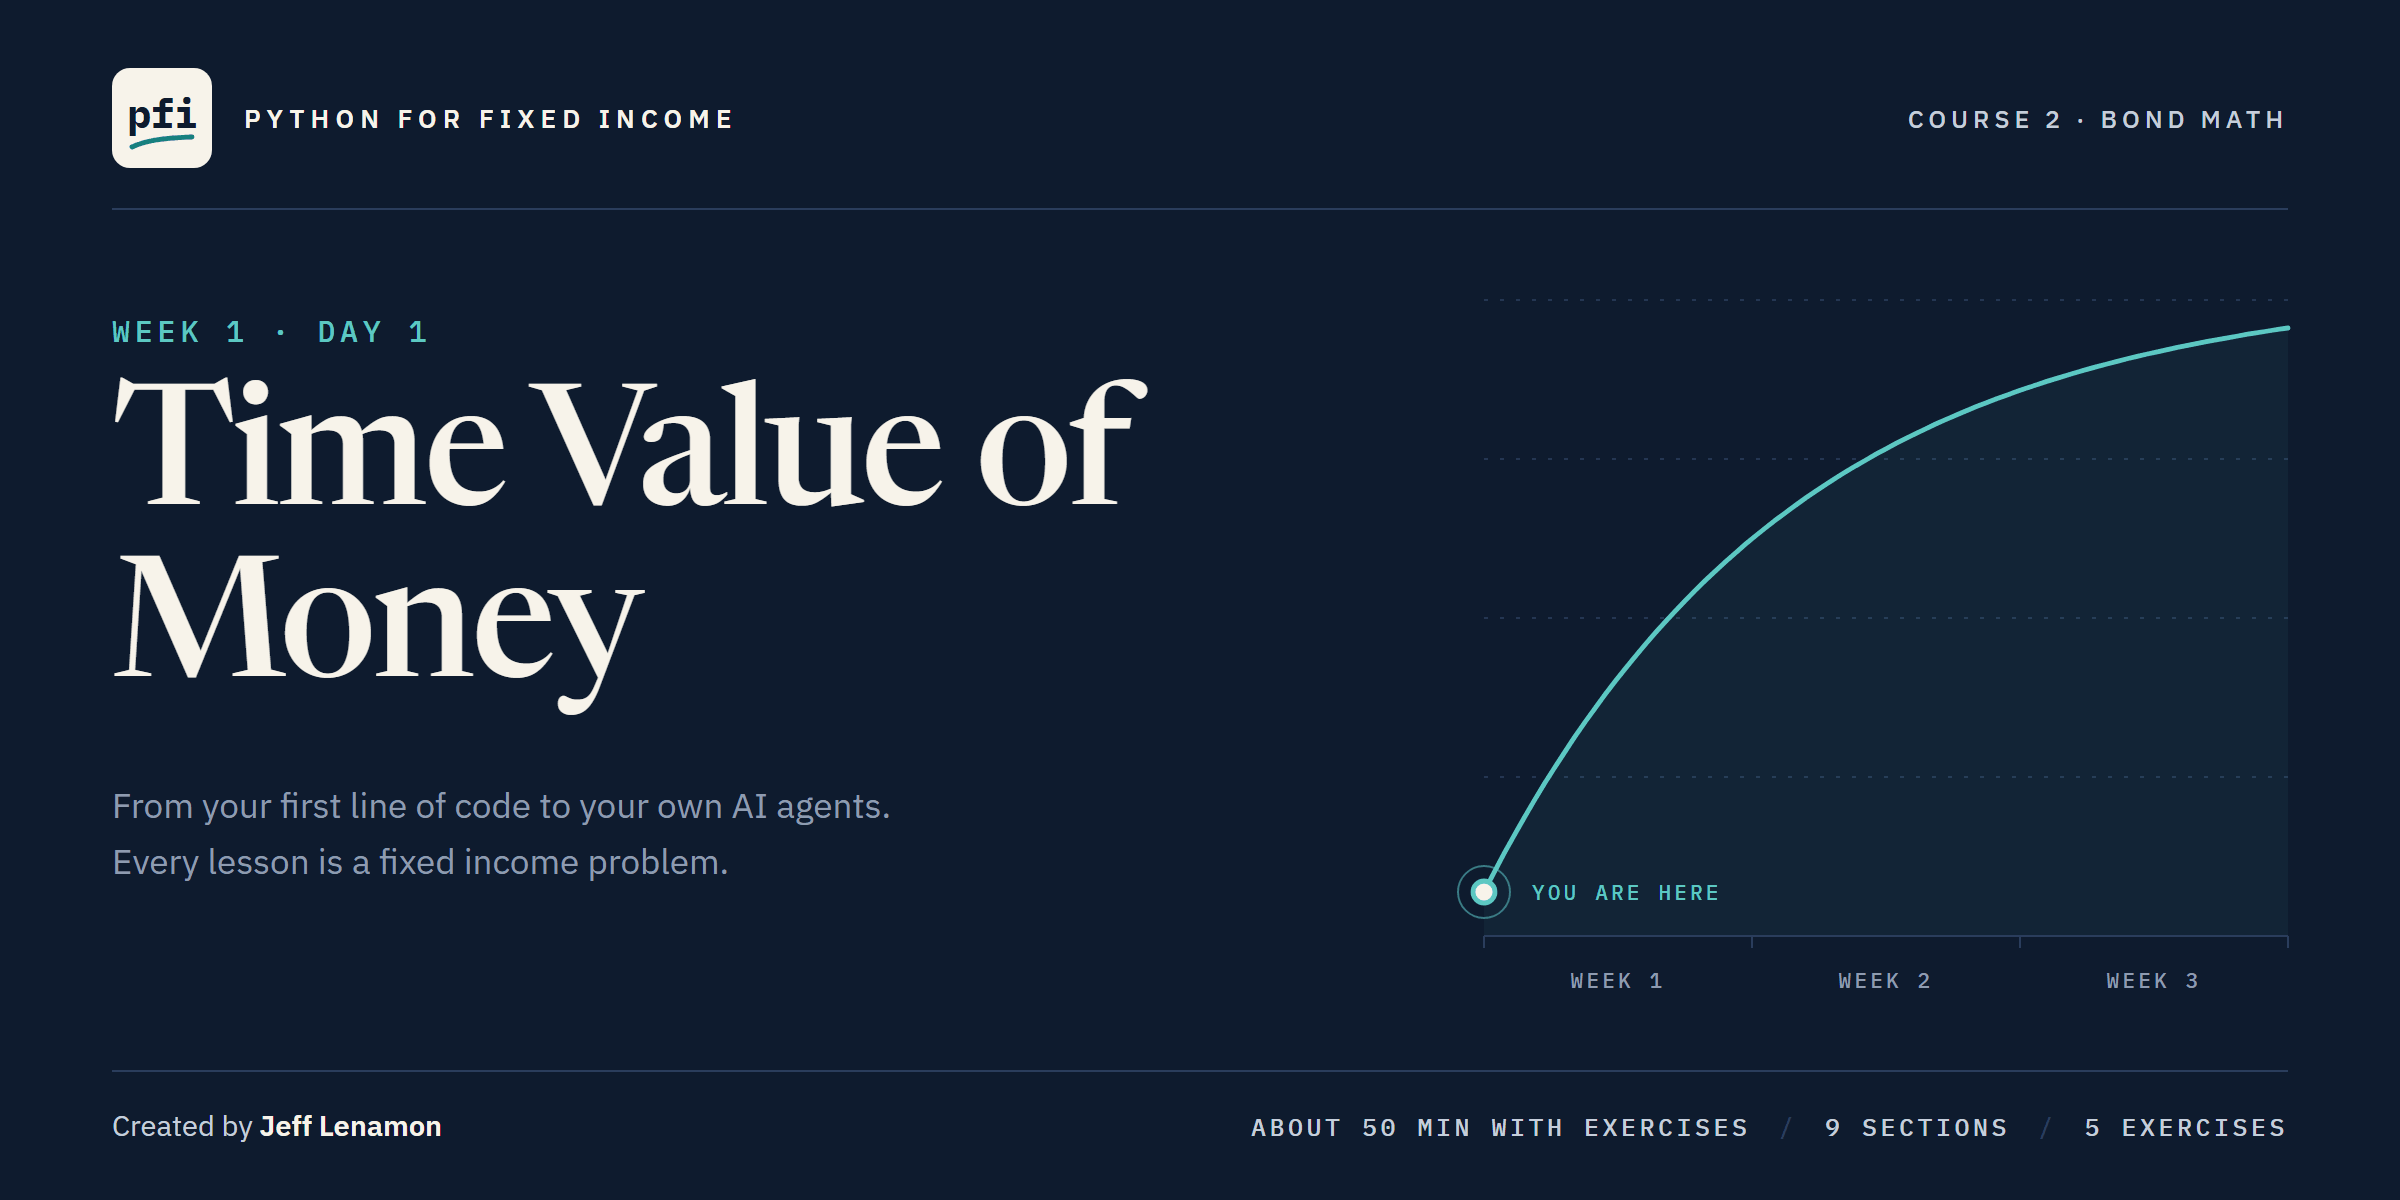

# Time Value of Money

Week 1, Day 1. What 100 grows to, what 100 due later is worth today, and your first bond math functions, tested against Excel and saved with Git.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day1/01_time_value_of_money.ipynb)

### Welcome to Course 2

Course 1 ended with a project that tested a file against its cover note before trusting it.
Course 2 turns that habit on the bond math itself.
Over three weeks you write the desk's functions in one module of your own, test every one against Excel, and keep each day's work with Git.

### The Desk Lead's Note

> From today the desk computes its own prices, in one module you write, with Excel as the answer key. Four new bonds settle today, 30 September 2026. Start at the base: what 100 grows to at Quorvane's yield, and what each bond's 100 at maturity is worth today. Show me, in dollars, how much the compounding convention moves that. Put both functions in your own file, docstring first. Prove they match Excel on every row of the answer key. Save a version you can go back to, and take it home.

Two units hold in every function:

<table align="left">
<tr><th align="left">Unit</th><th align="left">Rule</th><th align="left">Example</th></tr>
<tr><td align="left">Rates in</td><td align="left">percent a year</td><td align="left"><code>5.4</code> is 5.40 percent</td></tr>
<tr><td align="left">Money out</td><td align="left">per 100 of face</td><td align="left">76.6118 for every 100</td></tr>
</table>
<br clear="left">

Excel takes decimals, so every Excel formula here divides by 100 in plain sight: `5.4/100`.
The issuers are invented; every number describes the data.

**Excel has the answers; today you write the code that matches them.**

## Your Route Through Day 1

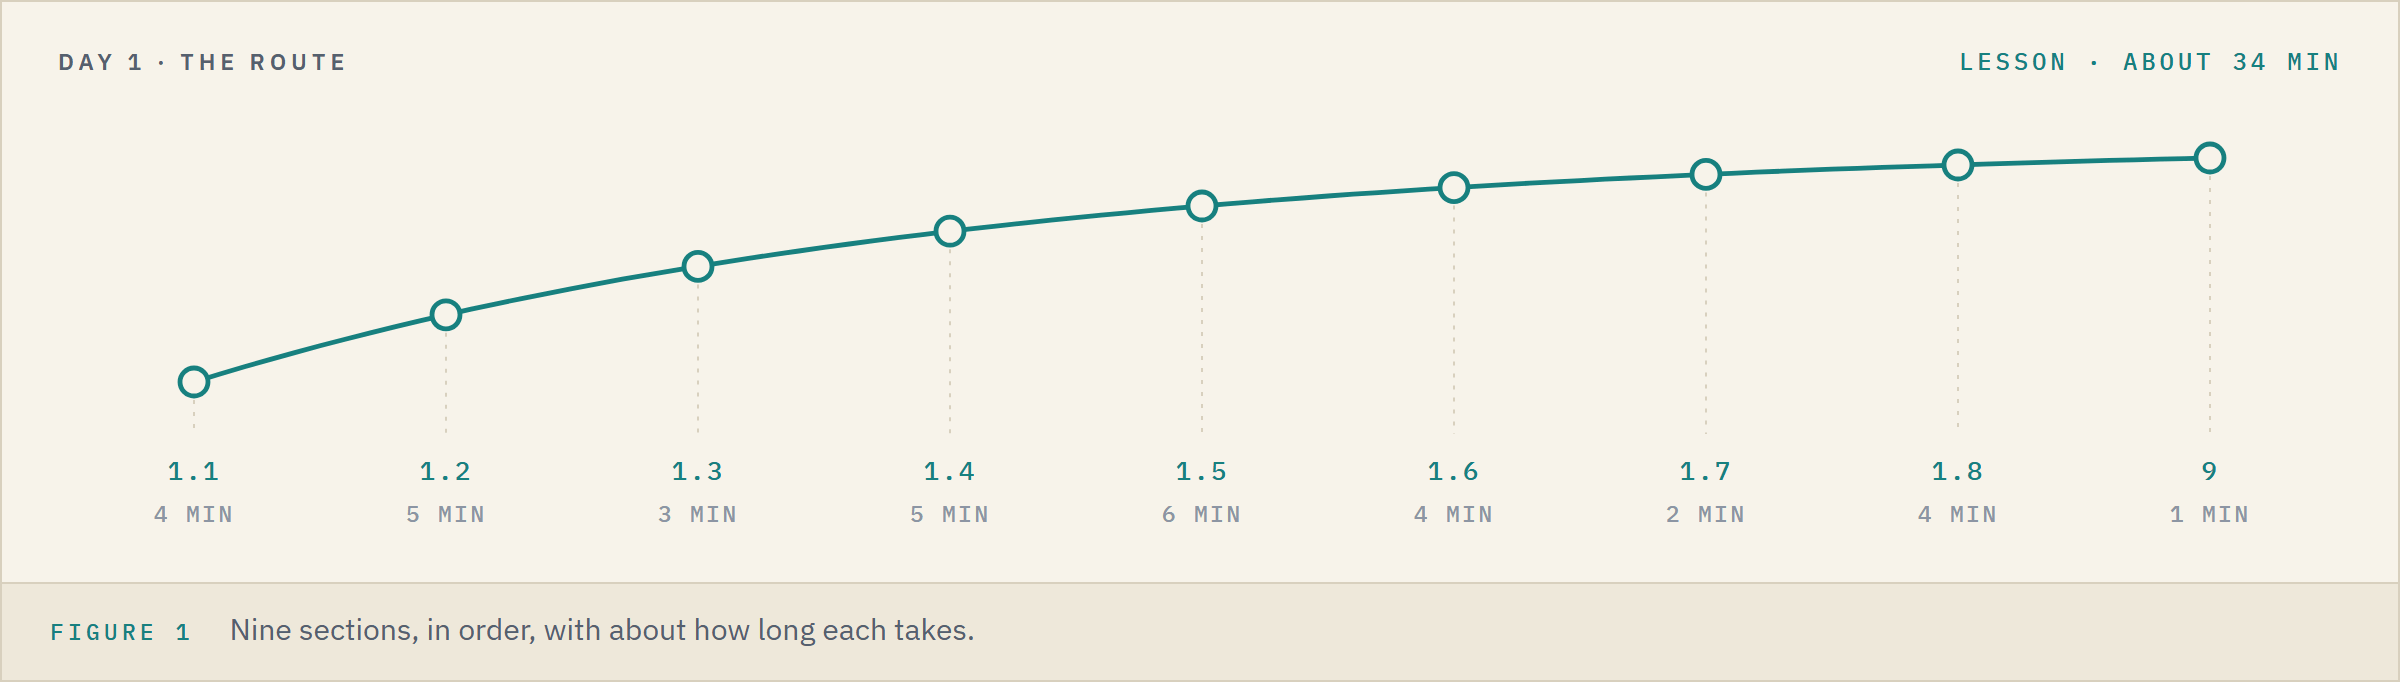

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">1.1</td><td align="left">The Work Folder</td><td align="left">4 min</td></tr>
<tr><td align="left">1.2</td><td align="left">Future Value</td><td align="left">5 min</td></tr>
<tr><td align="left">1.3</td><td align="left"><code>future_value</code> in Your Own Module</td><td align="left">3 min</td></tr>
<tr><td align="left">1.4</td><td align="left">Excel as the Answer Key: Your First pytest Run</td><td align="left">5 min</td></tr>
<tr><td align="left">1.5</td><td align="left">Present Value, Four Bonds</td><td align="left">6 min</td></tr>
<tr><td align="left">1.6</td><td align="left">One Rate, Three Frequencies</td><td align="left">4 min</td></tr>
<tr><td align="left">1.7</td><td align="left">A Test That Fails</td><td align="left">2 min</td></tr>
<tr><td align="left">1.8</td><td align="left">Save the Day With Git</td><td align="left">4 min</td></tr>
<tr><td align="left">9</td><td align="left">Bring It Home</td><td align="left">1 min</td></tr>
</table>
<br clear="left">

**Time.** About 34 minutes for the lesson, then about 15 for the five exercises.

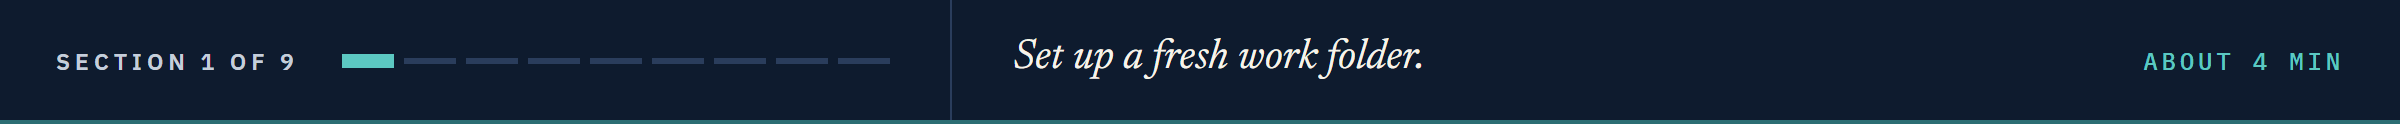

## 1.1 The Work Folder

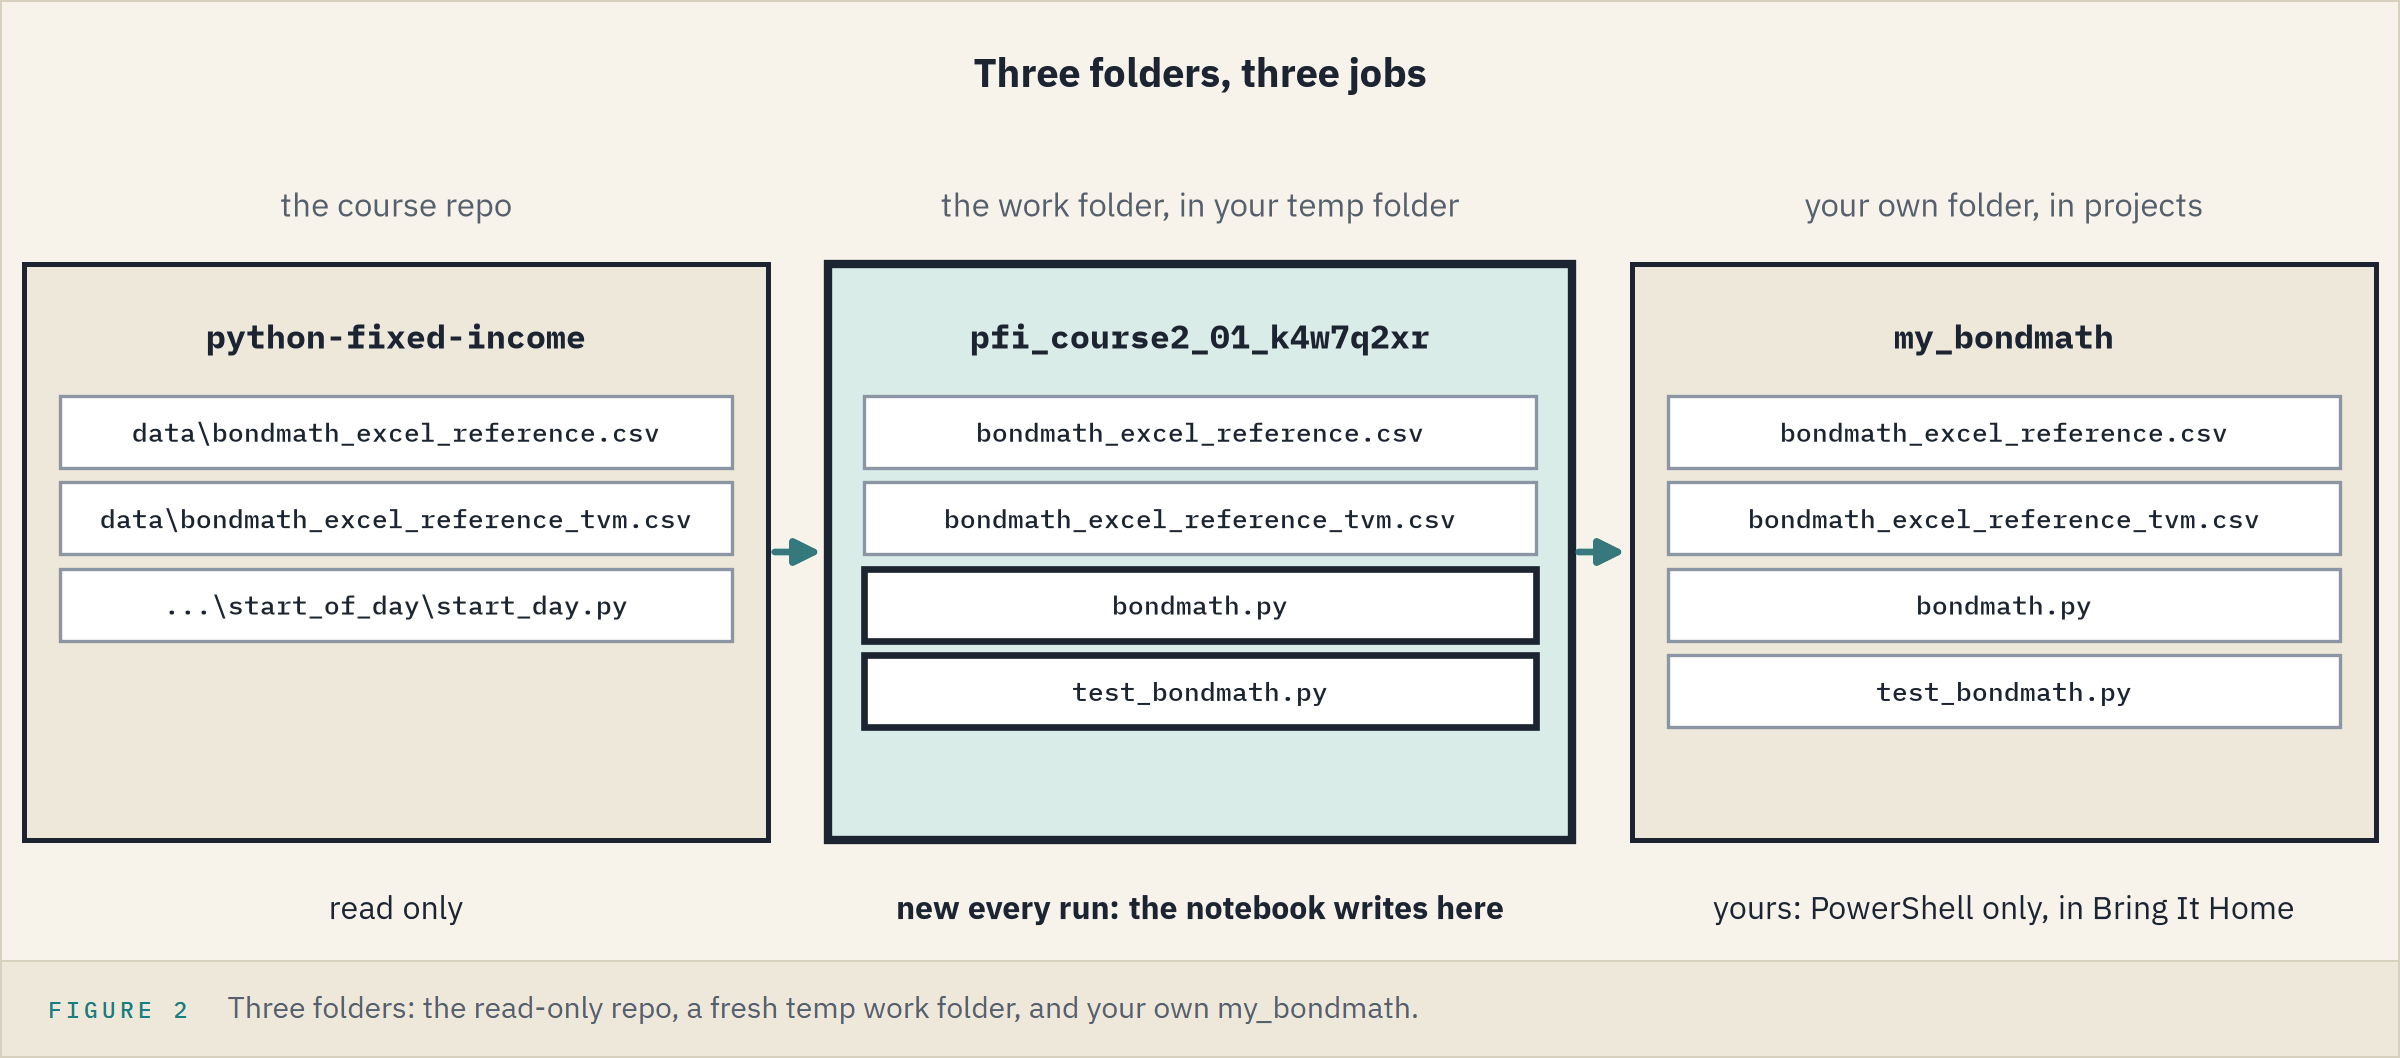

The work happens in a folder of its own, outside the course repo.

### Make Today's Work Folder

The first cell of every Course 2 notebook runs `start_day`, the course's helper.
It makes a new folder in your temp folder, moves the notebook into it, and copies in Excel's two answer files.
`sys.path.insert(0, folder)` puts a folder first on `sys.path`, the list of places Python looks for a module.
The cell looks for the course repo first and falls back to GitHub, as Course 1's pandas notebooks found the data folder.
A line that starts with `!` goes to the command line, not to Python, and `{github}` inside it is that name's value.
There `wget -q` downloads the helper quietly: Colab has no copy of the repo.

Q. Make today's work folder.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder holding the two Excel reference files.
# To start the day again, restart the kernel and run all cells.
work = start_day(1)

Work folder pfi_course2_01_k4w7q2xr: 2 data files, no module yet


Only the folder's name prints: its full path would show your user name.
`work` holds that path; every later step uses it.

### Imports and the House Colours

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])

### One Row of the Answer Key

Q. What did Excel return for 100 grown five years at Quorvane's 5.40 percent?

In [3]:
# Excel's answers for week 1 (TVM: time value of money), one row per formula, labelled by case_id
tvm = pd.read_csv('bondmath_excel_reference_tvm.csv', index_col='case_id')
print(len(tvm), 'rows. Row tvm_fv_09:')
print(tvm.loc['tvm_fv_09', 'excel_formula'], 'returned', tvm.loc['tvm_fv_09', 'excel_value'])

153 rows. Row tvm_fv_09:
=FV(5.4/100/2,2*5,0,-100) returned 130.52822611608937


Today's job: reach that number in code, then prove the code on every row like it.

### Today's Four Bonds

In [4]:
bonds = pd.DataFrame({
    'cusip': ['99001BZA7', '99002CZA4', '99003DZA1', '99004EZA8'],
    'issuer': ['Quorvane Energy', 'Dunmarrow Rail', 'Pellwick Paper', 'Halvering Foods'],
    'ticker': ['QVNE', 'DNMR', 'PLWK', 'HLVF'],
    'coupon_pct': [5.25, 6.125, 4.75, 7.5],
    'years': [5, 7, 3, 10],
    'yield_pct': [5.4, 6.125, 4.6, 7.7],
})
bonds

,cusip,issuer,ticker,coupon_pct,years,yield_pct
0,99001BZA7,Quorvane Energy,QVNE,5.250,5,5.400
1,99002CZA4,Dunmarrow Rail,DNMR,6.125,7,6.125
2,99003DZA1,Pellwick Paper,PLWK,4.750,3,4.600
3,99004EZA8,Halvering Foods,HLVF,7.500,10,7.700


Each settles today, a coupon date, and repays 100 on 30 September a whole number of years from now.

**The work folder holds Excel's answers; everything the notebook writes lands beside them.**

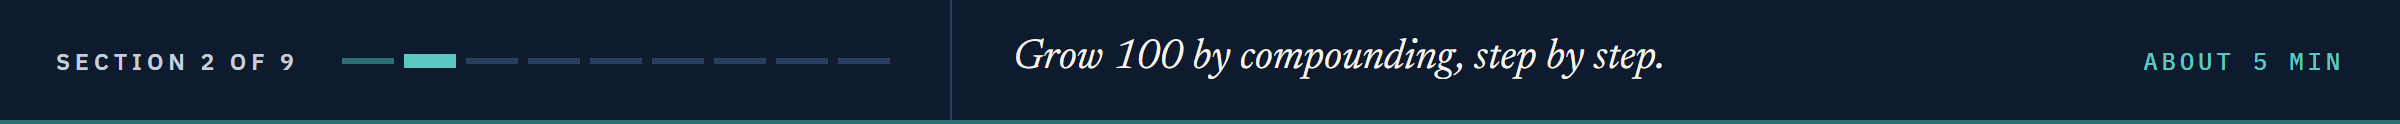

## 1.2 Future Value

At 5.40 percent a year, compounded twice a year, 100 earns half the annual rate each half-year, and from then on that interest earns interest too.
**Future value** is what the 100 has grown to at the end.

### One Half-Year

Q. What is 100 worth after one half-year?

In [5]:
# percent to a decimal, then half of it for one half-year
period_rate = 5.4 / 100 / 2
print(f'Half-year rate: {period_rate:.3f}. 100 after one half-year: {100 * (1 + period_rate):.2f}')

Half-year rate: 0.027. 100 after one half-year: 102.70


### Ten Half-Years

Q. Follow the 100 through all ten half-years of Quorvane's five years.

In [6]:
# each half-year, the whole balance, interest included, earns the half-year rate
value = 100
rows = []
for half_year in range(1, 11):
    value = value * (1 + period_rate)
    rows.append({'half_year': half_year, 'value': round(value, 4)})
growth = pd.DataFrame(rows)
growth

,half_year,value
0,1,102.7000
1,2,105.4729
2,3,108.3207
3,4,111.2453
4,5,114.2490
5,6,117.3337
6,7,120.5017
7,8,123.7552
8,9,127.0966
9,10,130.5282


Each step adds more than the one before: 2.70 in the first half-year, 3.43 in the last.

### Compound Against Simple

Q. Draw it beside **simple interest**, where only the original 100 earns.

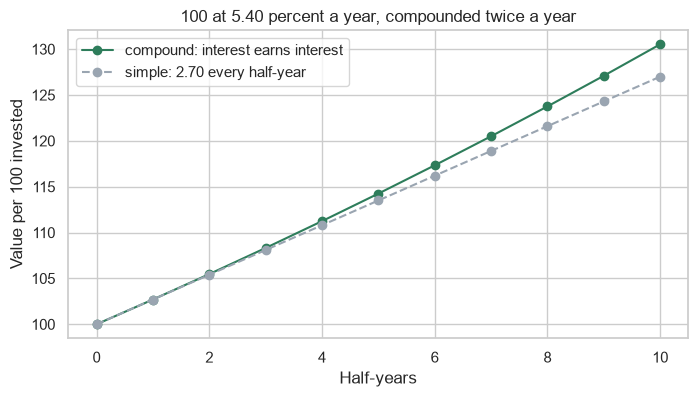

In [7]:
compound = [100] + list(growth['value'])
# simple interest adds the same 2.70 every half-year
simple = [100 + 100 * period_rate * k for k in range(11)]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(11), compound, marker='o', label='compound: interest earns interest')
ax.plot(range(11), simple, marker='o', linestyle='--', label='simple: 2.70 every half-year')
ax.set_title('100 at 5.40 percent a year, compounded twice a year')
ax.set_xlabel('Half-years')
ax.set_ylabel('Value per 100 invested')
ax.legend()
plt.show()

130.53 against 127.00: the gap, which widens every step, is interest earned on interest.

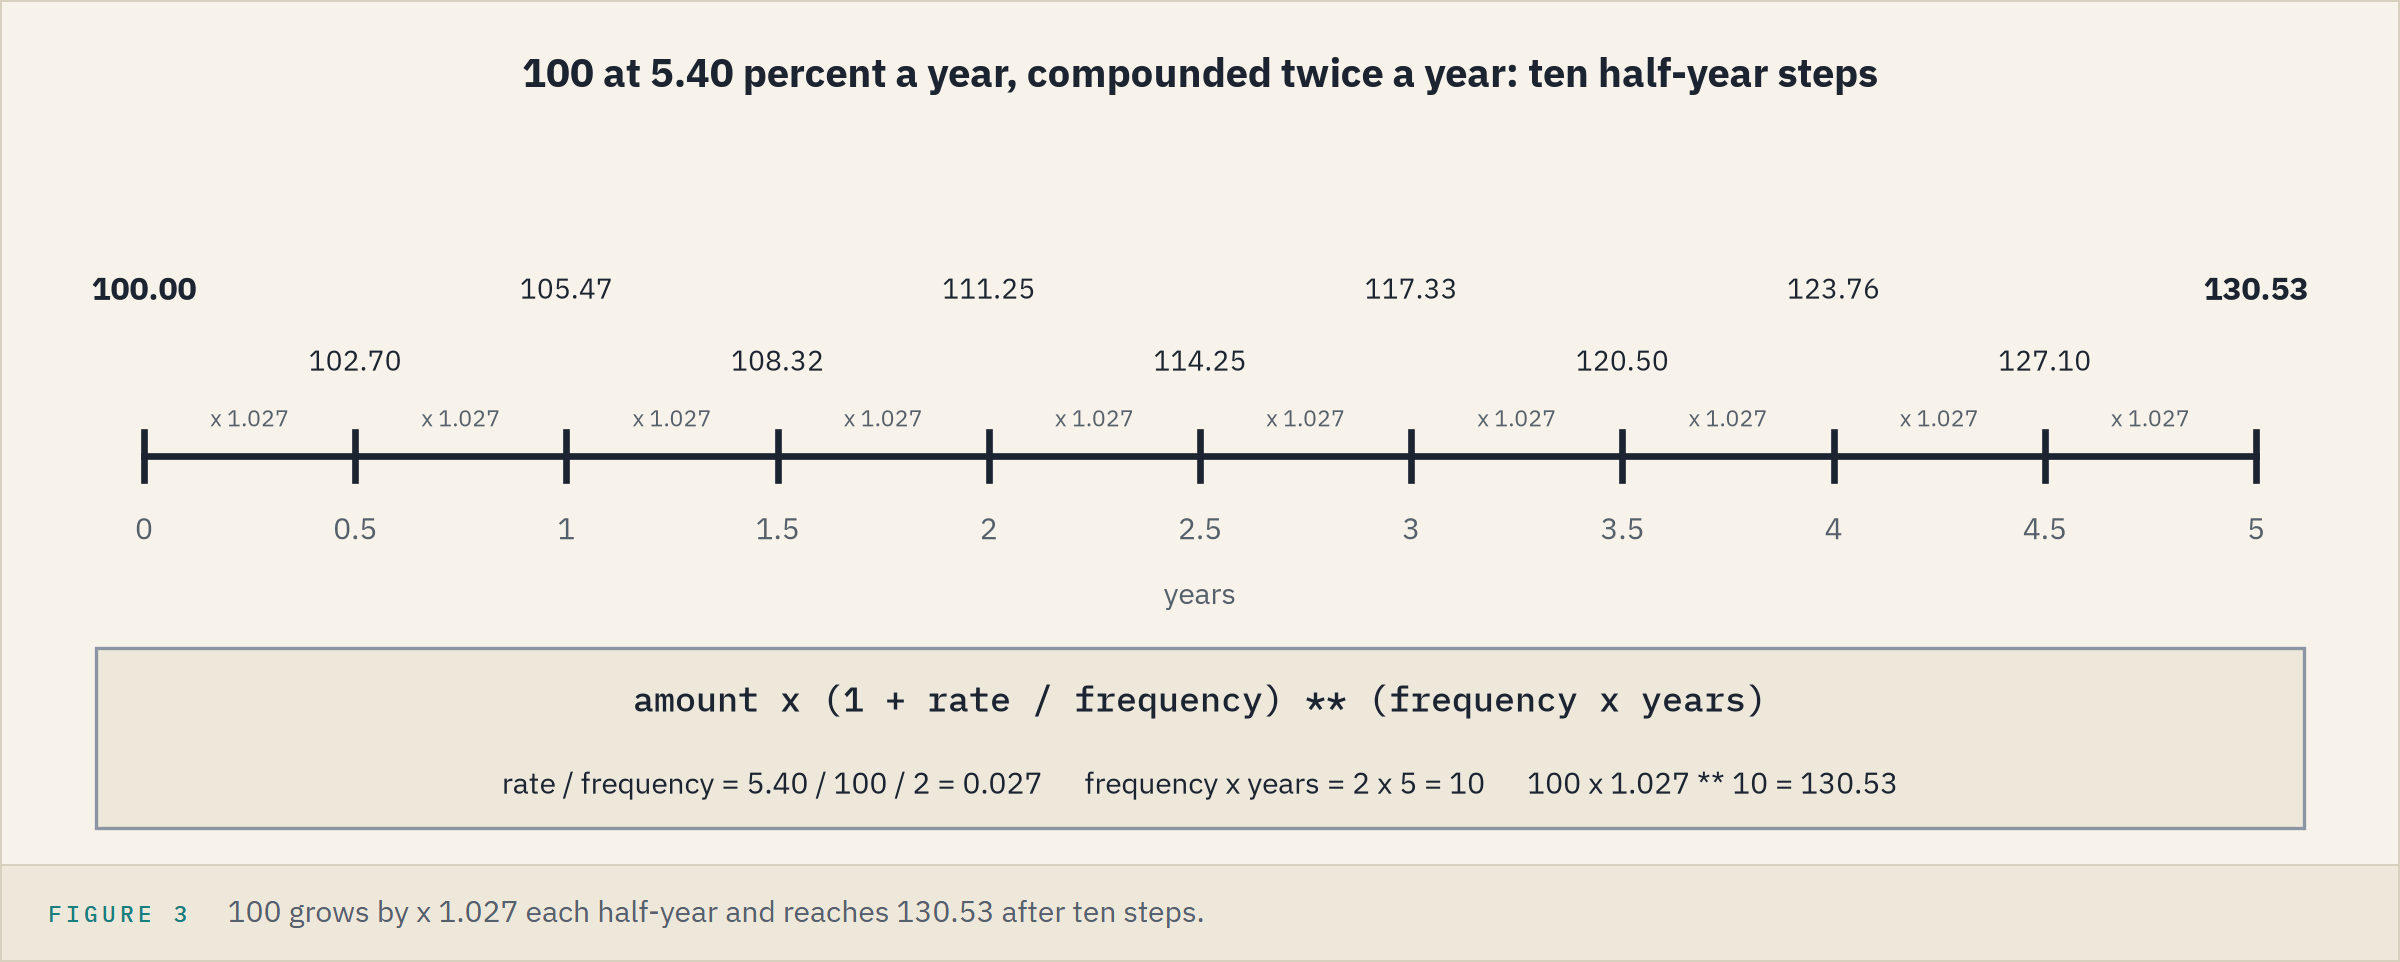

### The Formula

Multiply the ten steps together first: the result is the **growth factor**, and the loop becomes one line.
`**` is Excel's `^`, as in Course 1's Start Here.

Q. What does 1 grow to in ten half-years, and the 100?

In [8]:
# ten half-years: the same step, applied ten times
growth_factor = (1 + period_rate) ** (2 * 5)
print(f'Growth factor: {growth_factor:.4f}. Future value: {100 * growth_factor:.4f}')

Growth factor: 1.3053. Future value: 130.5282


Excel's 130.52822611608937, reached in one line.

**Predict 1**

The first five years added 30.53 to the 100.
Five more years at the same rate: what is it worth after ten?
Write down a number.

### Ten Years

In [9]:
ten_years = 100 * (1 + period_rate) ** (2 * 10)
second_five = ten_years - 100 * growth_factor
print(f'After ten years: {ten_years:.2f}. The second five years added {second_five:.2f}')

After ten years: 170.38. The second five years added 39.85


The second five years add 39.85, 1.3053 times the first five's 30.53: the same percent, on a bigger balance.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Growth column</td><td align="left">the loop</td><td align="left">100 in A1, <code>=A1*(1+5.4/100/2)</code> in A2, filled to A11</td><td align="left">130.5282</td></tr>
<tr><td align="left">Simple column</td><td align="left"><code>simple</code></td><td align="left">100 in D1, <code>=D1+100*5.4/100/2</code> in D2, filled to D11</td><td align="left">127.00</td></tr>
<tr><td align="left">Growth factor</td><td align="left"><code>(1 + period_rate) ** (2 * 5)</code></td><td align="left"><code>=(1+5.4/100/2)^(2*5)</code></td><td align="left">1.3053</td></tr>
<tr><td align="left">Future value</td><td align="left"><code>100 * growth_factor</code></td><td align="left"><code>=FV(5.4/100/2,2*5,0,-100)</code></td><td align="left">130.5282</td></tr>
<tr><td align="left">Ten years</td><td align="left"><code>ten_years</code></td><td align="left"><code>=100*(1+5.4/100/2)^(2*10)</code></td><td align="left">170.3762</td></tr>
</table>
<br clear="left">

`FV` takes the rate per period, the number of periods, a payment each period (0 here), and the amount entered as `-100`; it returns the grown amount as a positive number.

**One formula grows 100 to Excel's 130.5282: the loop, written once.**

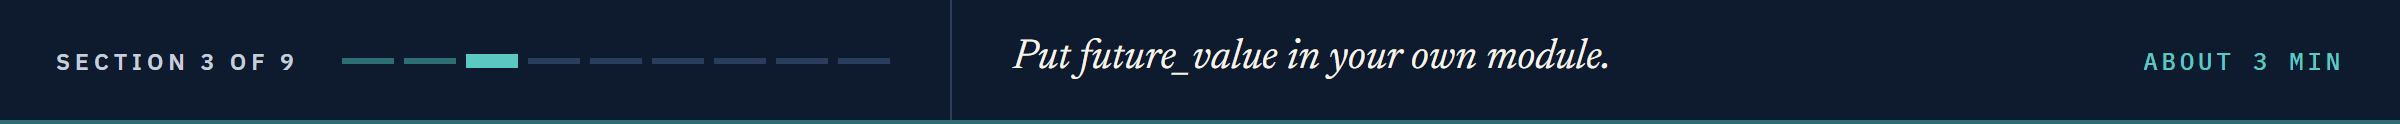

## 1.3 `future_value` in Your Own Module

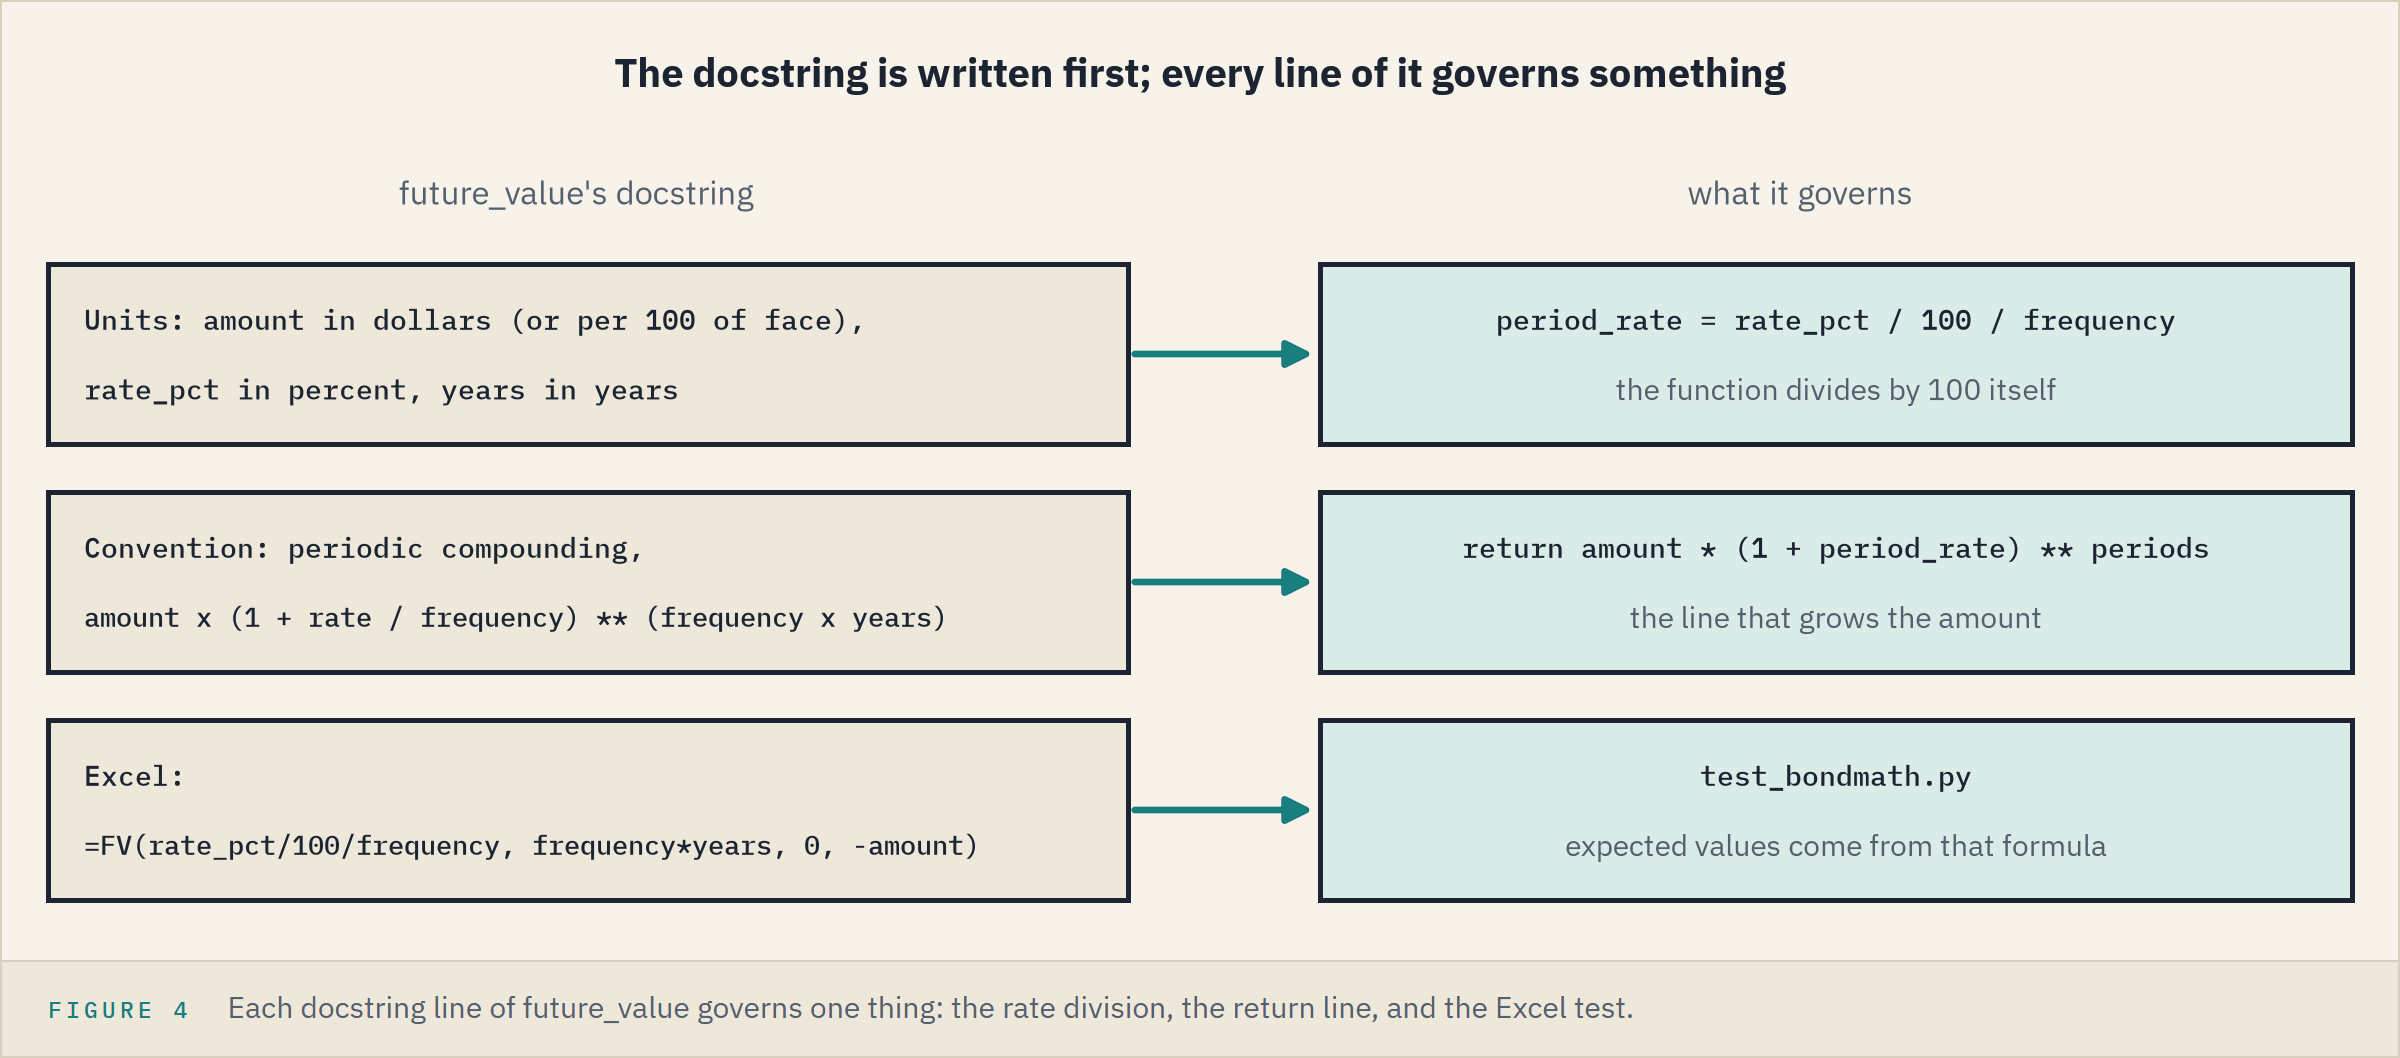

As in Course 1's From Notebook to Module, the functions go in a file: `bondmath.py`, one or two a day.
Each is written **docstring first**: units, convention, and the Excel formula that gives the same number, the request you would give a colleague or an AI assistant.

### Write `bondmath.py`

Q. Write the module's docstring and `future_value`.

In [10]:
%%writefile bondmath.py
"""bondmath: bond math for fixed-rate bullet bonds, checked against Excel.

Written day by day in Python for Fixed Income, Course 2: Bond Math.

Units, the same in every function:
- coupon_pct and yield_pct are annual rates in percent: 7.0 means 7 percent. Excel takes decimals (0.07).
- Prices and accrued interest are per 100 of face.
- Durations are in years, convexity in years squared, spreads in basis points.
- frequency is the number of coupons (or compounding periods) a year: 1, 2, or 4.
- basis is the day count: "30/360" (Excel basis 0) or "ACT/ACT" (Excel basis 1).
- Dates are datetime.date values.
"""


def future_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Grow an amount at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount x (1 + rate / frequency) ** (frequency x years).
    Excel: =FV(rate_pct/100/frequency, frequency*years, 0, -amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # grow the amount over every period
    return amount * (1 + period_rate) ** periods

Writing bondmath.py


The module's docstring sets the units every later function keeps.
The function refuses a frequency other than 1, 2 or 4, then takes 1.2's two steps.

### Import It

Q. Grow the 100 again, this time with the module.

In [11]:
# Python finds bondmath.py in the work folder, first on sys.path
import bondmath

print(bondmath.future_value(100, 5.4, 5))

130.5282261160894


Notice `5.4`, not `0.054`: percent in, as the docstring promises.
The frequency was left out, so its default, 2, applied.

### Ask It

In [12]:
help(bondmath.future_value)

Help on function future_value in module bondmath:

future_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float
    Grow an amount at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount x (1 + rate / frequency) ** (frequency x years).
    Excel: =FV(rate_pct/100/frequency, frequency*years, 0, -amount)



**The function lives in a file now, and its docstring says what it promises.**

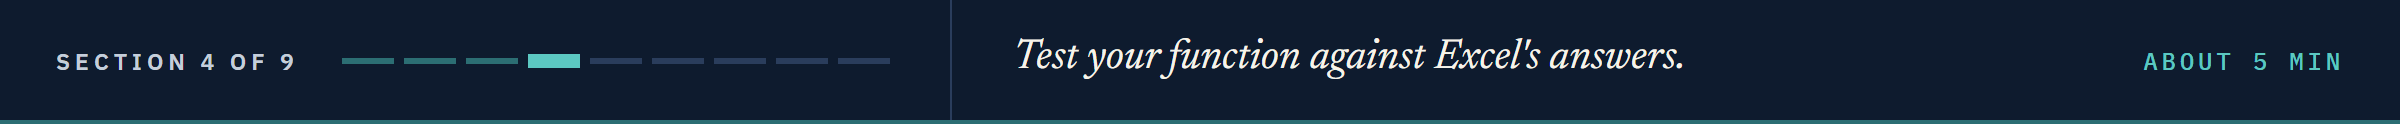

## 1.4 Excel as the Answer Key: Your First pytest Run

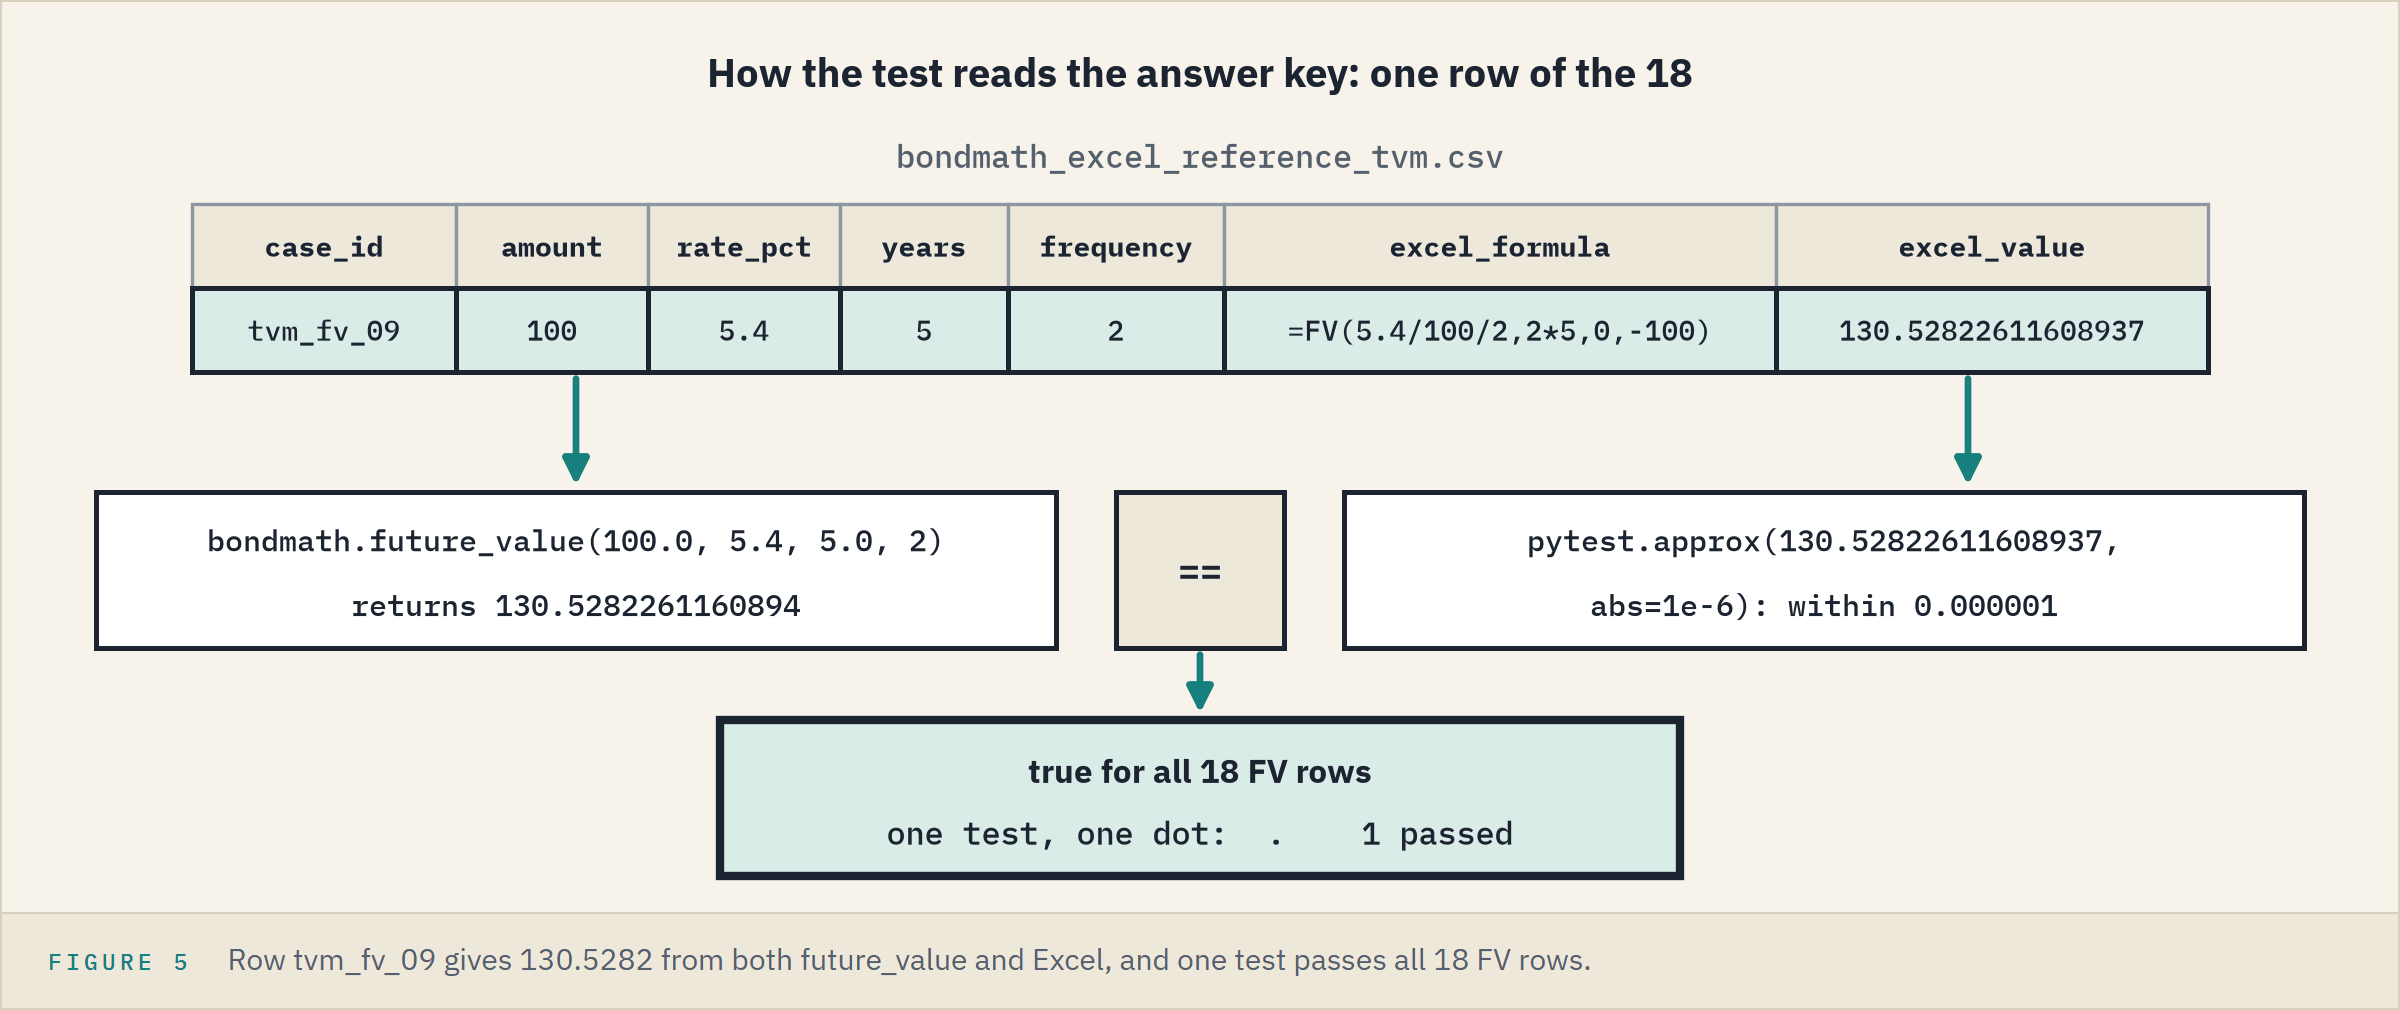

A **test** is an `assert` kept in a file, with its expected values from Excel, never from the code it tests.
pytest, named in Course 1's From Notebook to Module, runs every function whose name starts with `test_` in every file whose name starts with `test_`.

### Write `test_bondmath.py`

`__file__` is the test file's own path, so `HERE` is its folder, where the reference files sit.
`/` joins a folder and a file name into a path, as `os.path.join` did in Course 1's Files and Folders: `HERE / file_name`.
`read_rows` reads a CSV with that notebook's `csv.DictReader`, every value as text.
`tvm_rows('FV')` keeps one function's rows, and `assert rows` stops a test that would check nothing.
`pytest.approx(x, abs=1e-6)` stands for x give or take 0.000001, so `==` passes inside that gap.

Q. Write the top of the test file and the first test.

In [13]:
%%writefile test_bondmath.py
"""Tests for bondmath.py.

Every expected value comes from Excel: the two reference CSV files in this folder, or a small hand
table whose values those files confirm. Run from this folder with:  python -m pytest
"""
import csv
from pathlib import Path

import pytest

import bondmath

# the reference files sit in the same folder as this test file
HERE = Path(__file__).parent


def read_rows(file_name: str) -> list[dict]:
    """Read a reference CSV from this folder: one dict per row, every value a string."""
    with open(HERE / file_name, newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))


TVM = read_rows("bondmath_excel_reference_tvm.csv")


def tvm_rows(function: str) -> list[dict]:
    """The week 1 reference rows for one Excel function, for example "FV"."""
    rows = [row for row in TVM if row["function"] == function]
    assert rows, f"no {function} rows in the reference file"
    return rows


def test_future_value_matches_excel_fv():
    for row in tvm_rows("FV"):
        # the inputs, in course units
        amount, rate_pct = float(row["amount"]), float(row["rate_pct"])
        years, frequency = float(row["years"]), int(row["frequency"])
        result = bondmath.future_value(amount, rate_pct, years, frequency)
        # Excel's FV, with the amount entered as -amount, is positive
        assert result == pytest.approx(float(row["excel_value"]), abs=1e-6), row["case_id"]

Writing test_bondmath.py


### Run pytest

`subprocess.run` runs a program and waits: here this notebook's own Python (`sys.executable`) runs pytest's short report (`-m pytest -q`) in the work folder (`cwd=work`), keeping what it prints as text for the cell to print.
`-p no:cacheprovider` leaves no cache folder behind.
pytest starts fresh, so it reads both files as they are on disk now.

In [14]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.                                                                        [100%]
1 passed in 0.50s



One dot, `1 passed`: one test, every FV row of the answer key within 0.000001.

**Excel side by side.** A check column does the same job for one row: Python's 130.5282261160894 in A2, `=FV(5.4/100/2,2*5,0,-100)` in B2, and `=ABS(A2-B2)<0.000001` in C2 shows TRUE.

### How Many Excel Numbers

Q. Which rows did that one test read?

In [15]:
fv_rows = tvm[tvm['function'] == 'FV']
print(len(fv_rows), 'FV rows:', fv_rows['years'].min(), 'to', fv_rows['years'].max(), 'years,',
      fv_rows['rate_pct'].min(), 'to', fv_rows['rate_pct'].max(), 'percent')
print('Rows by frequency:', fv_rows['frequency'].value_counts().sort_index().to_dict())

18 FV rows: 0.5 to 30.0 years, 0.5 to 8.6 percent
Rows by frequency: {1: 2, 2: 13, 4: 3}


### Where the Rows Sit

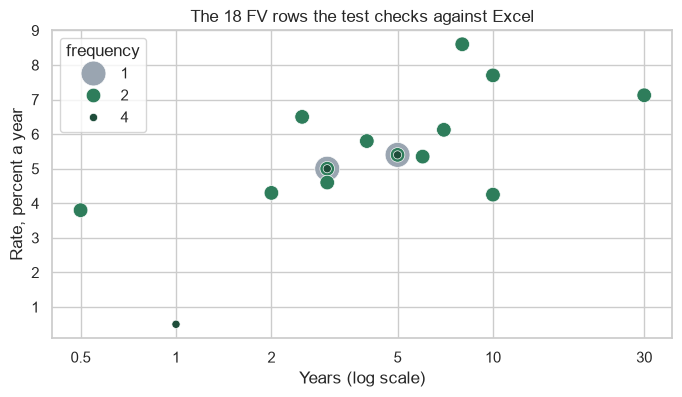

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
# size= sizes each dot by frequency, sizes= sets each area; annual first, so big dots sit under
sns.scatterplot(data=fv_rows.sort_values('frequency'), x='years', y='rate_pct', hue='frequency',
                size='frequency', sizes={1: 320, 2: 110, 4: 35},
                palette=['#9AA5B1', '#2E7D5B', '#1E4D3A'], ax=ax)
# a log scale spreads the short terms out, as set_yscale('log') did in the Visualization notebook
ax.set_xscale('log')
ax.set_xticks([0.5, 1, 2, 5, 10, 30], ['0.5', '1', '2', '5', '10', '30'])
ax.set_title('The 18 FV rows the test checks against Excel')
ax.set_xlabel('Years (log scale)')
ax.set_ylabel('Rate, percent a year')
plt.show()

Short and long, low rate and high, all three frequencies: at 3 and 5 years the dots nest, Quorvane's among them.
A test only covers the cases it reads.

**`1 passed`: your function agrees with Excel on all 18 FV rows.**

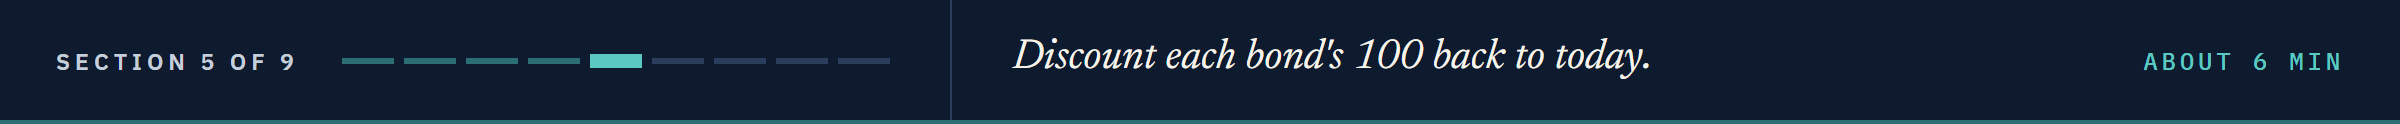

## 1.5 Present Value, Four Bonds

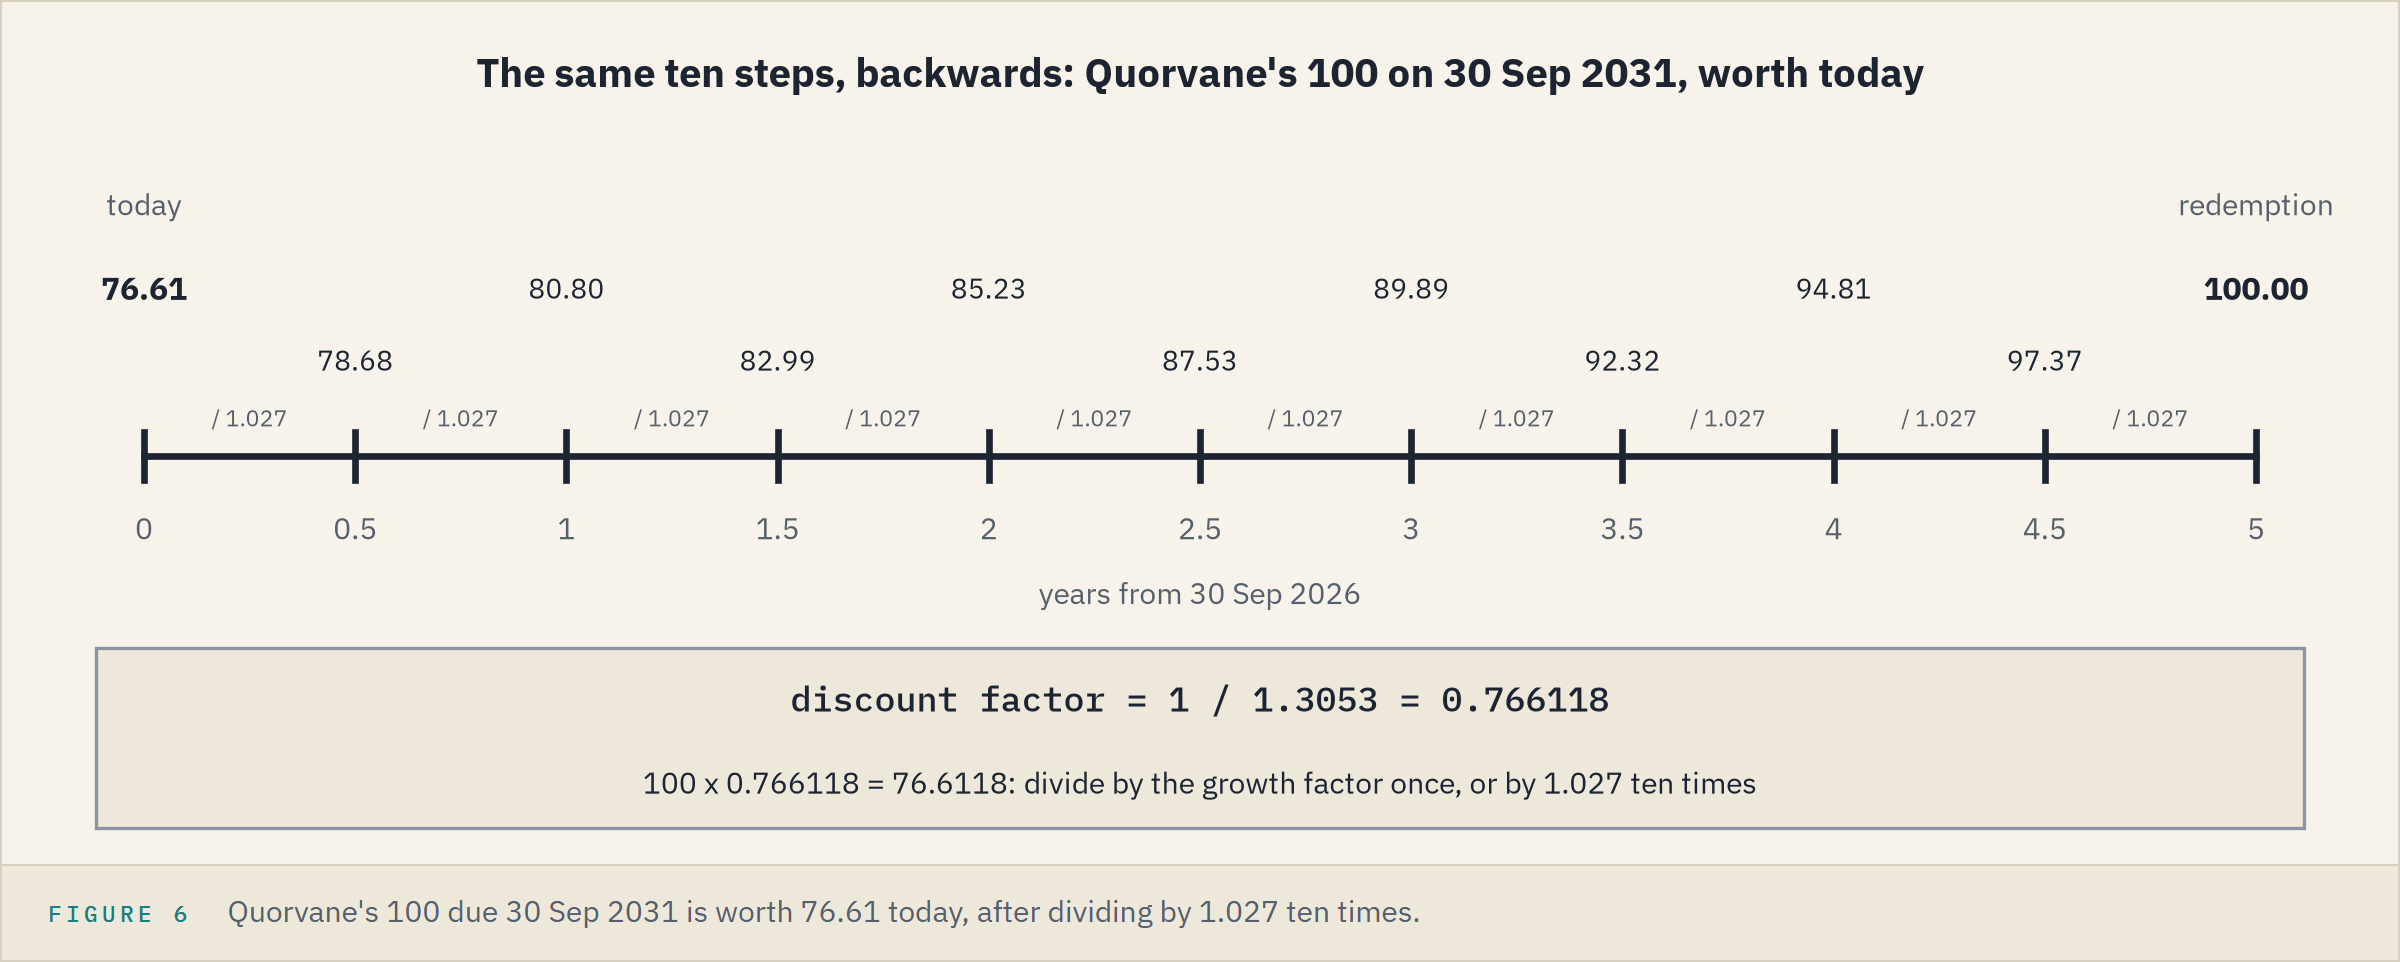

Quorvane repays 100 on 30 September 2031, its **redemption**.
Its value today is the same ten steps run backwards.
1 divided by the growth factor is the discount factor of Course 1's Introduction, Part 1.

### Append `present_value`

Q. Add `present_value` to the module, docstring first.

In [17]:
%%writefile -a bondmath.py


def present_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Discount an amount due in `years` at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount / (1 + rate / frequency) ** (frequency x years).
    Returns a positive number for a positive amount. Excel's PV returns the same number with a
    minus sign: =-PV(rate_pct/100/frequency, frequency*years, 0, amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # discount the amount over every period
    return amount / (1 + period_rate) ** periods

Appending to bondmath.py


The docstring settles the sign before anyone is surprised by it: positive here, negative from Excel's `PV`.

### Every Bond's 100, Today

Q. What is each bond's 100 at maturity worth today, at its own yield?

In [18]:
import importlib

# read the file again: the module in memory does not have present_value yet
importlib.reload(bondmath)
bonds['pv_of_100'] = [bondmath.present_value(100, y, t)
                      for y, t in zip(bonds['yield_pct'], bonds['years'])]
table = bonds[['ticker', 'years', 'yield_pct', 'pv_of_100']]
table.style.format({'yield_pct': '{:.3f}', 'pv_of_100': '{:.4f}'}).hide(axis='index')

ticker,years,yield_pct,pv_of_100
QVNE,5,5.400,76.6118
DNMR,7,6.125,65.5527
PLWK,3,4.600,87.2461
HLVF,10,7.700,46.9753


A higher rate and a longer wait both push a present value down.

### Discount Factor Against Time

Q. Draw the discount factor from today to ten years at each bond's yield, with a dot at each maturity.

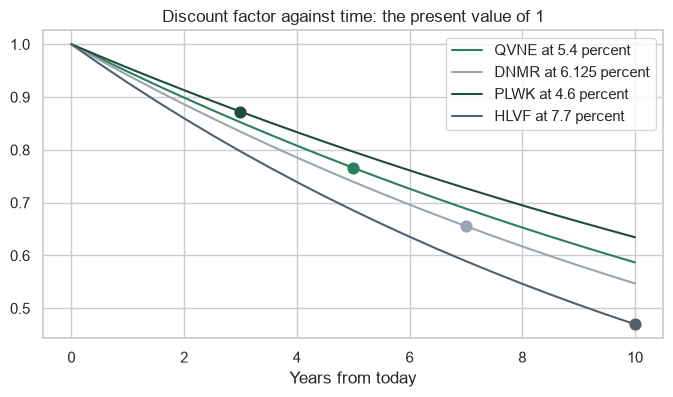

In [19]:
half_years = [k / 2 for k in range(21)]
colours = ['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D']
fig, ax = plt.subplots(figsize=(8, 4))
for ticker, y, t, colour in zip(bonds['ticker'], bonds['yield_pct'], bonds['years'], colours):
    factors = [bondmath.present_value(1, y, k) for k in half_years]
    ax.plot(half_years, factors, color=colour, label=f'{ticker} at {y} percent')
    ax.scatter(t, bondmath.present_value(1, y, t), color=colour, s=60, zorder=3)
ax.set_title('Discount factor against time: the present value of 1')
ax.set_xlabel('Years from today')
ax.legend()
plt.show()

Every line starts at 1 today and falls with the wait; the higher the yield, the faster.
The dots are the table's numbers divided by 100.

**Predict 2**

Quorvane's 100 is worth 76.61 today at 5.40 percent.
The yield doubles to 10.80 percent.
What is the 100 worth today?

A) near 38: the rate doubled, so the value halves

B) near 59: the value falls, by less than a quarter

C) near 75: the 100 has not changed, so the value barely moves

### Twice the Yield

In [20]:
doubled = bondmath.present_value(100, 10.8, 5)
fall = (1 - doubled / bonds.loc[0, 'pv_of_100']) * 100
print(f'At 10.80 percent: {doubled:.4f}, down {fall:.1f} percent from 76.6118')

At 10.80 percent: 59.1009, down 22.9 percent from 76.6118


B: the rate sits inside a power, so doubling it does not halve the value.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Discount factor</td><td align="left"><code>bondmath.present_value(1, 5.4, 5)</code></td><td align="left"><code>=1/(1+5.4/100/2)^(2*5)</code> or <code>=-PV(5.4/100/2,2*5,0,1)</code></td><td align="left">0.766118</td></tr>
<tr><td align="left">Present value, written out</td><td align="left"><code>bondmath.present_value(100, 5.4, 5)</code></td><td align="left"><code>=100/(1+5.4/100/2)^(2*5)</code></td><td align="left">76.6118</td></tr>
<tr><td align="left">Excel's <code>PV</code></td><td align="left"></td><td align="left"><code>=PV(5.4/100/2,2*5,0,100)</code></td><td align="left">-76.6118</td></tr>
<tr><td align="left"><code>PV</code>, sign turned</td><td align="left"></td><td align="left"><code>=-PV(5.4/100/2,2*5,0,100)</code></td><td align="left">76.6118</td></tr>
<tr><td align="left">Twice the yield</td><td align="left"><code>doubled</code></td><td align="left"><code>=100/(1+10.8/100/2)^(2*5)</code></td><td align="left">59.1009</td></tr>
</table>
<br clear="left">

`PV` returns money received later as money paid now: negative.
`present_value` returns it positive, so its test compares with minus Excel's value.

### Two More Tests

The second test needs no Excel: grow 100 for 3 years at 5 percent, discount it back, and 100 must return at every frequency.

Q. Append a test against the 18 PV rows, and the round trip.

In [21]:
%%writefile -a test_bondmath.py


def test_present_value_matches_excel_pv():
    for row in tvm_rows("PV"):
        amount, rate_pct = float(row["amount"]), float(row["rate_pct"])
        years, frequency = float(row["years"]), int(row["frequency"])
        result = bondmath.present_value(amount, rate_pct, years, frequency)
        # Excel's PV of a positive amount is negative (money paid now), so compare with minus the Excel value
        assert result == pytest.approx(-float(row["excel_value"]), abs=1e-6), row["case_id"]


def test_present_value_undoes_future_value():
    for frequency in (1, 2, 4):
        # grow 100 for 3 years at 5 percent, then discount it back
        grown = bondmath.future_value(100, 5.0, 3, frequency)
        assert bondmath.present_value(grown, 5.0, 3, frequency) == pytest.approx(100, abs=1e-9)

Appending to test_bondmath.py


### Run pytest Again

In [22]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...                                                                      [100%]
3 passed in 0.50s



**Discounting is growth run backwards, and `3 passed` covers both directions.**

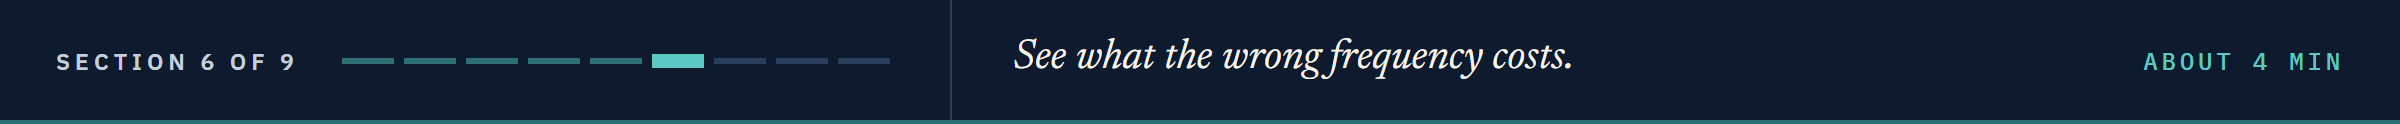

## 1.6 One Rate, Three Frequencies

A rate of 5.40 percent a year can be applied once, twice, or four times a year.
The course's bonds compound twice; a yield is not complete without its frequency.

### Annual, Semiannual, Quarterly

Q. Grow and discount Quorvane's 100 at 5.40 percent for 5 years, at each frequency.

In [23]:
for frequency in [1, 2, 4]:
    grown = bondmath.future_value(100, 5.4, 5, frequency)
    today = bondmath.present_value(100, 5.4, 5, frequency)
    print(f'{frequency} a year: grows to {grown:.4f}, worth {today:.4f} today')

1 a year: grows to 130.0778, worth 76.8771 today
2 a year: grows to 130.5282, worth 76.6118 today
4 a year: grows to 130.7600, worth 76.4760 today


More often means more interest on interest: a higher future value and a lower present value.

### What the Wrong Frequency Costs

Q. Discount each bond's 100 annually instead of semiannually: how many dollars does that move on 10,000,000 of face?

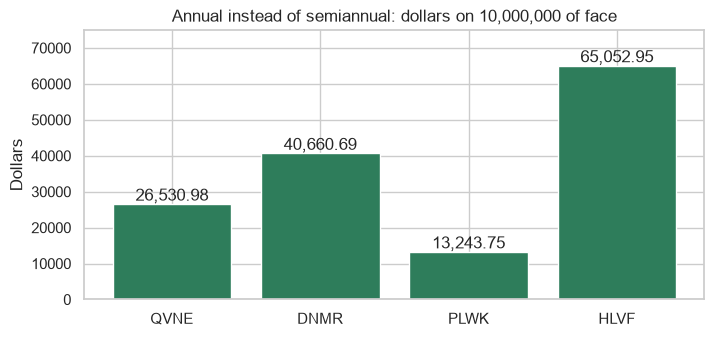

In [24]:
bonds['annual_pv'] = [bondmath.present_value(100, y, t, 1)
                      for y, t in zip(bonds['yield_pct'], bonds['years'])]
# per 100 of face, so times 100,000 for 10,000,000 of face
bonds['wrong_by_dollars'] = (bonds['annual_pv'] - bonds['pv_of_100']) * 100_000
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(bonds['ticker'], bonds['wrong_by_dollars'])
# the {} form of fmt allows the thousands comma
ax.bar_label(bars, fmt='{:,.2f}')
ax.set_ylim(0, 75_000)
ax.set_title('Annual instead of semiannual: dollars on 10,000,000 of face')
ax.set_ylabel('Dollars')
plt.show()

Halvering, the longest at the highest yield, moves most: 65,052.95 dollars.
That is a **convention error**: the code runs, the number looks reasonable, and it is wrong.

### A Frequency the Module Refuses

Q. What does the module do with a monthly frequency, 12?

In [25]:
bondmath.future_value(100, 5.4, 5, frequency=12)

ValueError: frequency must be 1, 2, or 4, not 12

It refuses rather than guessing: a monthly number would look just as reasonable.

**Predict 3**

No bond here pays daily, but the formula does not care.
5.40 percent compounded 365 times a year: where does the 100 end after five years?
Write down a number.

### Every Day of the Year

In [26]:
# the formula written out: the module refuses 365
daily = 100 * (1 + 5.4 / 100 / 365) ** (365 * 5)
quarterly = bondmath.future_value(100, 5.4, 5, 4)
print(f'Daily: {daily:.4f}, only {daily - quarterly:.4f} above quarterly')

Daily: 130.9938, only 0.2338 above quarterly


The ceiling is NumPy Part 2's continuous compounding: 130.9964.

**Excel side by side.** The frequency sits twice in each formula: in the rate and in the periods.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Annual, grown</td><td align="left"><code>bondmath.future_value(100, 5.4, 5, 1)</code></td><td align="left"><code>=FV(5.4/100/1,1*5,0,-100)</code></td><td align="left">130.0778</td></tr>
<tr><td align="left">Annual, today</td><td align="left"><code>bondmath.present_value(100, 5.4, 5, 1)</code></td><td align="left"><code>=PV(5.4/100/1,1*5,0,100)</code></td><td align="left">-76.8771</td></tr>
<tr><td align="left">Quarterly, grown</td><td align="left"><code>bondmath.future_value(100, 5.4, 5, 4)</code></td><td align="left"><code>=FV(5.4/100/4,4*5,0,-100)</code></td><td align="left">130.7600</td></tr>
<tr><td align="left">Quarterly, today</td><td align="left"><code>bondmath.present_value(100, 5.4, 5, 4)</code></td><td align="left"><code>=PV(5.4/100/4,4*5,0,100)</code></td><td align="left">-76.4760</td></tr>
<tr><td align="left">Daily, grown</td><td align="left"><code>daily</code></td><td align="left"><code>=100*(1+5.4/100/365)^(365*5)</code></td><td align="left">130.9938</td></tr>
</table>
<br clear="left">

**A yield is not complete without its frequency: the wrong one moves Halvering by 65,052.95 dollars, and nothing warns you.**

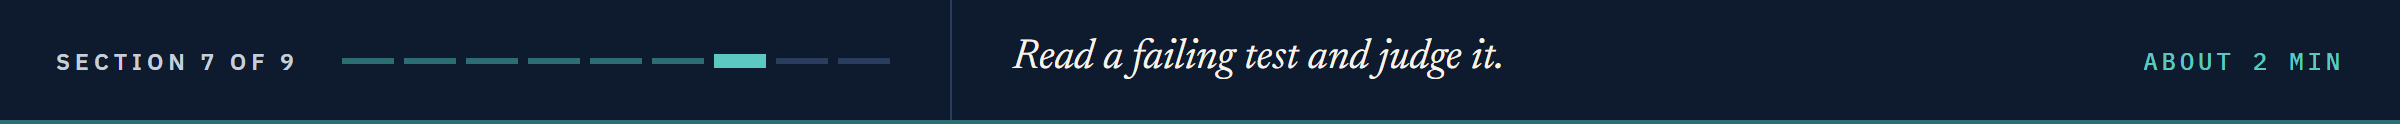

## 1.7 A Test That Fails

A colleague writes a quick test of Quorvane's present value against Excel's `PV`, exactly as Excel returns it.

### A Colleague's Test

In [27]:
%%writefile test_excel_sign.py
"""A colleague's quick test: Quorvane against Excel's PV as Excel returns it."""
import pandas as pd
import pytest

import bondmath


def test_quorvane_against_excel_pv():
    excel = pd.read_csv('bondmath_excel_reference_tvm.csv', index_col='case_id')
    # Quorvane: 100 due in 5 years at 5.40 percent, semiannual
    expected = excel.loc['tvm_pv_09', 'excel_value']
    assert bondmath.present_value(100, 5.4, 5) == pytest.approx(expected, abs=1e-6)

Writing test_excel_sign.py


### Run That File Only

A file name after the command runs only that file.

In [28]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_excel_sign.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

F                                                                        [100%]
================================== FAILURES ===================================
_______________________ test_quorvane_against_excel_pv ________________________

    def test_quorvane_against_excel_pv():
        excel = pd.read_csv('bondmath_excel_reference_tvm.csv', index_col='case_id')
        # Quorvane: 100 due in 5 years at 5.40 percent, semiannual
        expected = excel.loc['tvm_pv_09', 'excel_value']
>       assert bondmath.present_value(100, 5.4, 5) == pytest.approx(expected, abs=1e-6)
E       assert 76.61178196895271 == -76.61178196895273 ± 1.0e-06
E         
E         comparison failed
E         Obtained: 76.61178196895271
E         Expected: -76.61178196895273 ± 1.0e-06

test_excel_sign.py:12: AssertionError
=========================== short test summary info ===========================
FAILED test_excel_sign.py::test_quorvane_against_excel_pv - assert 76.61178196895271 == -76.61178196895273 ± 1

`F` instead of a dot, and `1 failed`.
Read it from the bottom, as in Course 1's Debugging notebook: the last line counts the failures, the one above names the test.
The `>` line is the `assert`; the `E` line gives the two numbers, equal apart from the sign.
The function is right and the test is wrong: `test_bondmath.py` already compares with minus Excel's value.

### Delete It

In [29]:
os.remove('test_excel_sign.py')
print(sorted(os.listdir()))

['__pycache__', 'bondmath.py', 'bondmath_excel_reference.csv', 'bondmath_excel_reference_tvm.csv', 'test_bondmath.py']


`__pycache__` is where Python keeps compiled copies of the modules it imports; leave it alone.

**A failing test says two things disagree; deciding which is wrong is your job.**

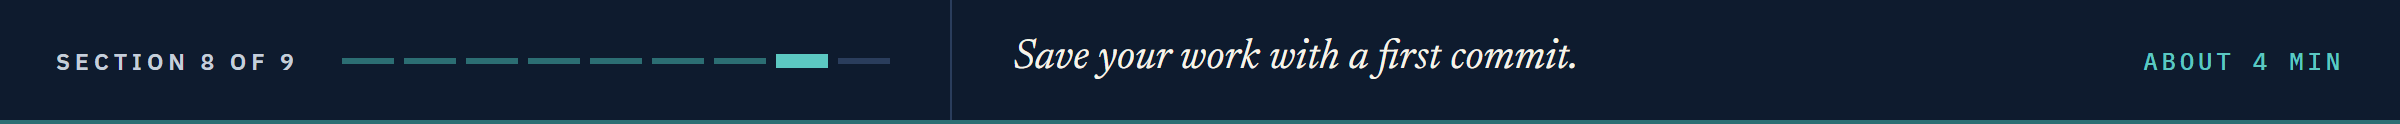

## 1.8 Save the Day With Git

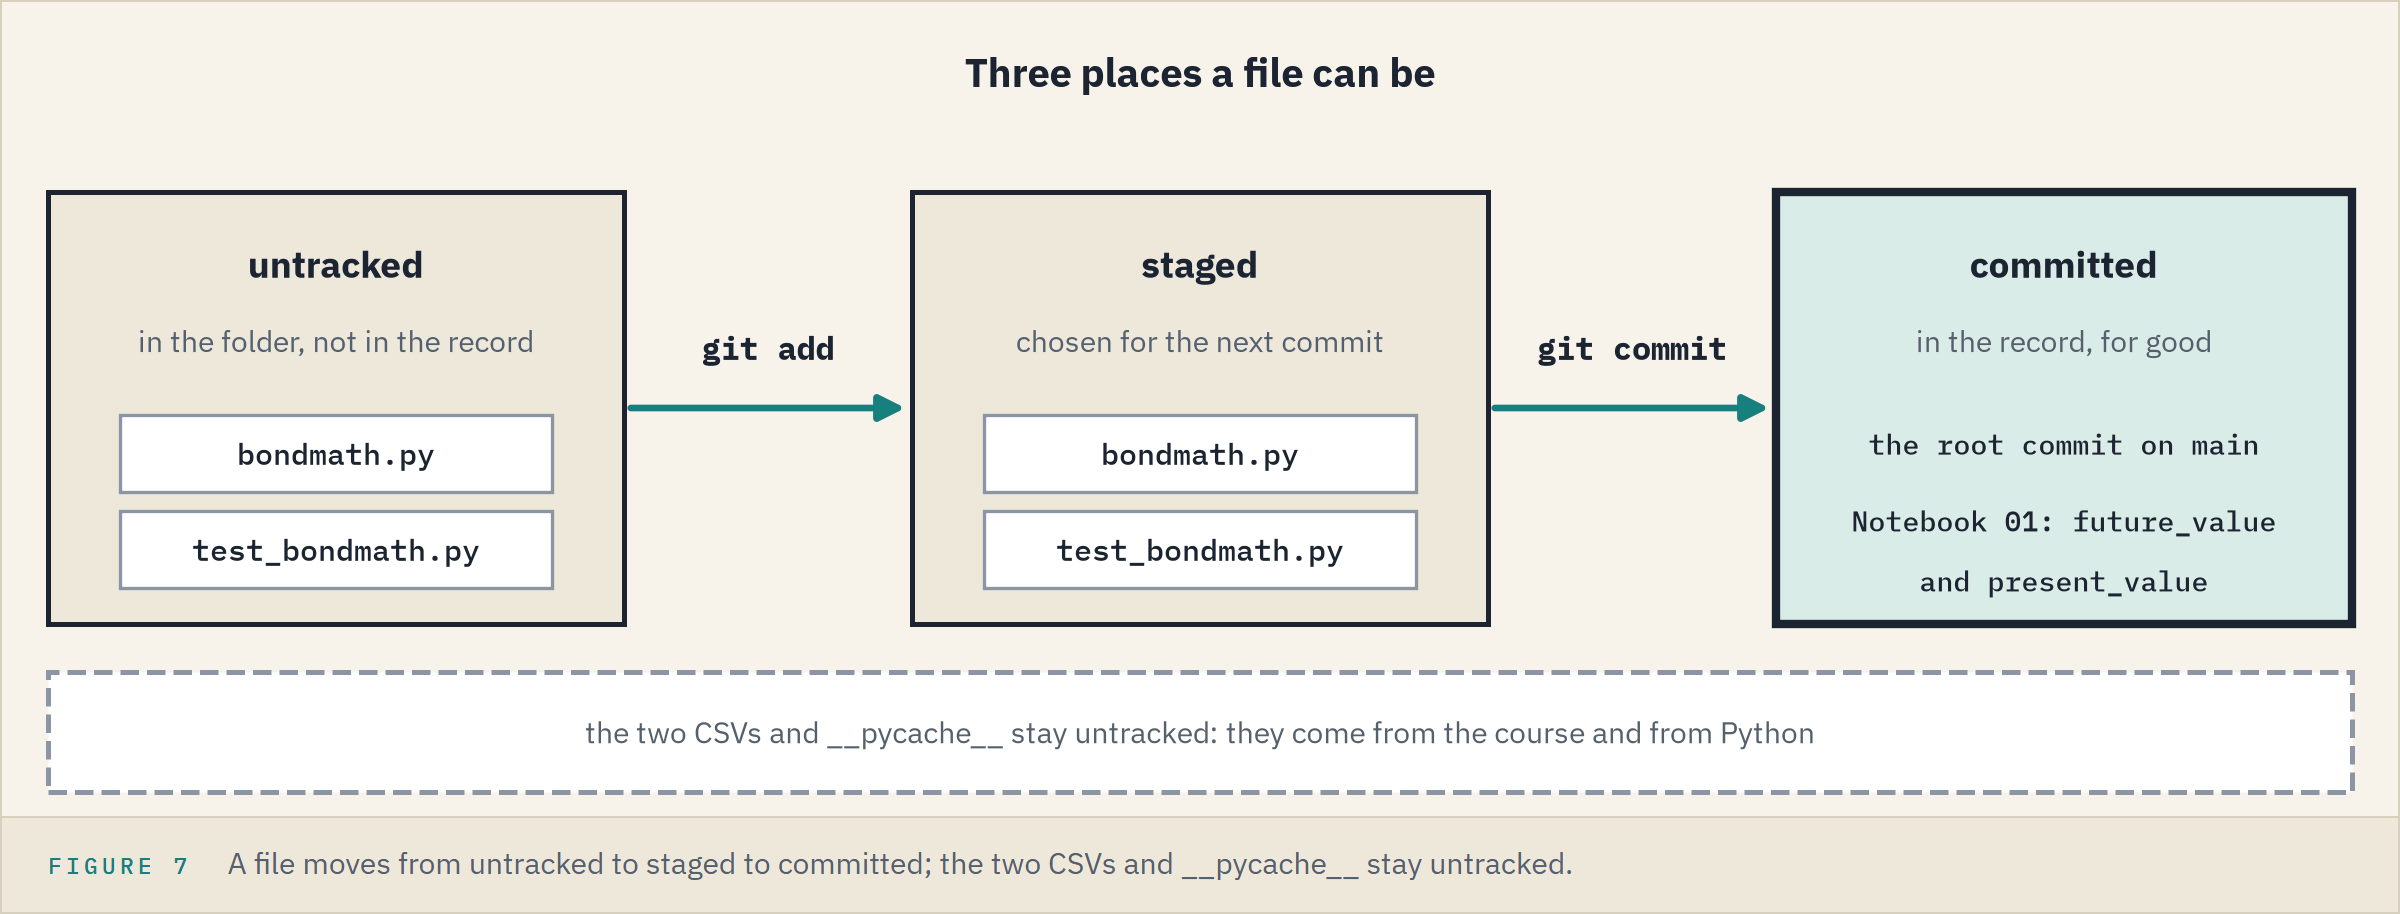

**Git** keeps every version of the files in a folder.
The folder is a **repository**, and each saved version a **commit**, with a message saying what changed.

**Excel side by side.** Save As with a date keeps whole copies; a commit keeps each version with a message and the exact lines that changed.

**Installing Git.** Colab has it.
On Windows, install Git for Windows from [git-scm.com/downloads](https://git-scm.com/downloads) with the default choices, as your firm's policy allows, then restart VS Code.

### Make the Work Folder a Repository

The cell, piece by piece, with `!` and `{work}` as in the setup cell:
* `shutil.which('git')` finds Git, or the cell stops with the install steps.
* `-C "{work}"` points Git at the work folder, never at the course repo around this notebook.
* `init -q -b main` makes the repository quietly; its line of commits, its **branch**, is `main`.
* The `config` lines hold for this repository only.
* `top = !git ...` keeps what Git prints as a list; `os.path.samefile` checks that Git's top folder is the work folder.

In [30]:
import os
import shutil

# stop here, with the steps to install it, if Git is not on this machine
if shutil.which('git') is None:
    raise RuntimeError('Git is not installed. Install Git for Windows from '
                       'https://git-scm.com/downloads, restart VS Code, and run this cell again.')
# make the work folder a repository: -C "{work}" points every Git command at the work folder
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, an example email, line endings kept, no signing
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false
# the guard: Git's top folder must be the work folder, or the notebook stops here
top = !git -C "{work}" rev-parse --show-toplevel
assert os.path.samefile(top[0], work), 'Git is not in the work folder: run the setup cell again'
print('Git is working in', work.name, 'and nowhere else')

Git is working in pfi_course2_01_k4w7q2xr and nowhere else


### What Git Sees

In [31]:
# --short: one line per file
!git -C "{work}" status --short

?? __pycache__/
?? bondmath.py
?? bondmath_excel_reference.csv
?? bondmath_excel_reference_tvm.csv
?? test_bondmath.py


Git sees every file in the folder: `??` marks one it keeps no record of, an **untracked** file.
You choose what to commit by naming the files: today, the two you wrote.

### Stage the Two Files

In [32]:
# git add chooses files for the next commit
!git -C "{work}" add bondmath.py test_bondmath.py
!git -C "{work}" status --short

A  bondmath.py
A  test_bondmath.py
?? __pycache__/
?? bondmath_excel_reference.csv
?? bondmath_excel_reference_tvm.csv


`A` marks a file staged for the next commit; the `??` files stay out.

### The First Commit

In [33]:
!git -C "{work}" commit -m "Notebook 01: future_value and present_value"

[main (root-commit) d029474] Notebook 01: future_value and present_value
 2 files changed, 105 insertions(+)
 create mode 100644 bondmath.py
 create mode 100644 test_bondmath.py


`root-commit` because it is the first; then the **commit hash**, the commit's name, and the message.
Both files, every line added.

**Today's two files are in the record, and every later change can be read line by line.**

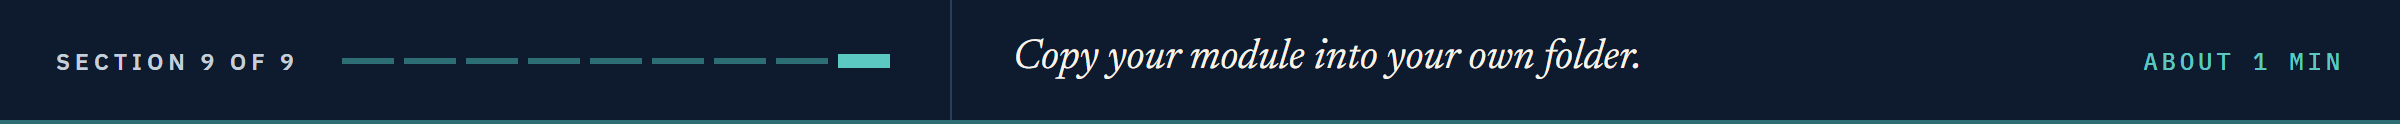

## Bring It Home

Your own copy lives in `my_bondmath`, beside the course repo; no notebook touches it.
In a VS Code PowerShell terminal with the course's `.venv` active, run these lines with your own work folder, name and email:

```powershell
# the work folder the setup cell printed
$work = "$env:TEMP\pfi_course2_01_k4w7q2xr"
# make my_bondmath (Out-Null hides the listing) and move into it
New-Item -ItemType Directory -Force "$HOME\projects\my_bondmath" | Out-Null
Set-Location "$HOME\projects\my_bondmath"
# copy in the two files and Excel's answers, then run the tests and commit
Copy-Item "$work\bondmath.py", "$work\test_bondmath.py" .
Copy-Item "$work\bondmath_excel_reference.csv", "$work\bondmath_excel_reference_tvm.csv" .
python -m pytest -q
git init -q -b main
git config user.name "Your Name"
git config user.email "you@example.com"
git add bondmath.py test_bondmath.py
git commit -m "Notebook 01: future_value and present_value"
```

```
...                                                                      [100%]
3 passed in 0.50s
```

Git then reports the root commit, "Notebook 01: future_value and present_value", and its 2 files.
In Colab the work folder is under `/tmp`: open it in the file browser on the left and download the two `.py` files.
If Git is blocked on your laptop, read the output above.
The work folder can stay: a restart makes a new one.

**Your own `my_bondmath` holds the module, its tests, and their first commit.**

## You Can Now

By the end of this notebook, you can:

* Grow an amount with one formula: future value.
* Bring a payment back to today: present value.
* Spot a convention error in the frequency.
* Write a function docstring first.
* Test a module against Excel's answers with pytest, and read a pass and a failure.
* Read Excel's `FV` and `PV` with their sign.
* Make a first commit and take the files home.

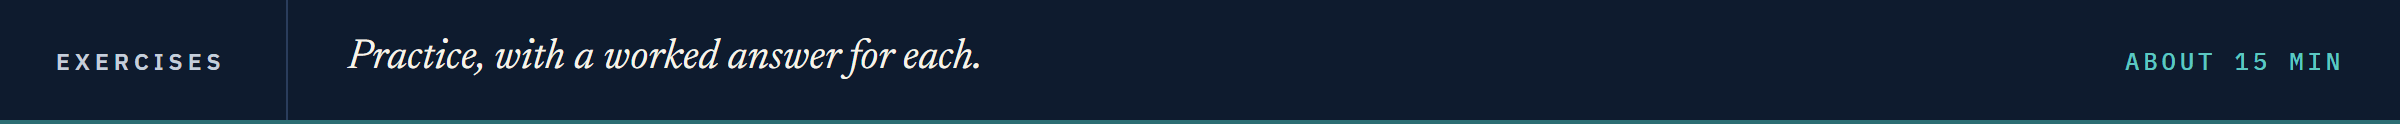

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

A second desk bought four more bonds on 30 September 2026.
Replace each `...` with your own code, then run the cell.
Run the next two cells first: the bonds and `check`.

In [34]:
exercise_bonds = pd.DataFrame({
    'issuer': ['Ostrevale Telecom', 'Tarnwick Utilities', 'Osmere Chemicals', 'Calderby Retail'],
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'years': [4, 2, 6, 8],
    'yield_pct': [5.8, 4.3, 5.35, 8.6],
})
exercise_bonds

,issuer,ticker,years,yield_pct
0,Ostrevale Telecom,OSTV,4,5.80
1,Tarnwick Utilities,TRNW,2,4.30
2,Osmere Chemicals,OSMC,6,5.35
3,Calderby Retail,CLDB,8,8.60


In [35]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

Q. What is each bond's 100 at maturity worth today? Store Osmere's, unrounded, in **ex1_osmere** and the lowest one's ticker in **ex1_lowest**.

In [36]:
ex1_osmere = ...
ex1_lowest = ...
check('Exercise 1 Osmere', ex1_osmere, 72.84897770986194)
check('Exercise 1 lowest', ex1_lowest, 'CLDB')

Exercise 1 Osmere: not attempted yet
Exercise 1 lowest: not attempted yet


### Exercise 2

Q. Build a discount factor ladder: `years` from 0.5 to 5.0 by half-years, and one column per ticker at its yield. Store it in **ex2_ladder**, its rows in **ex2_rows**, and Calderby's 5-year factor in **ex2_cldb_5y**.

In [37]:
ex2_ladder = ...
ex2_rows = ...
ex2_cldb_5y = ...
check('Exercise 2 rows', ex2_rows, 10)
check('Exercise 2 Calderby at 5 years', ex2_cldb_5y, 0.6563823821846481)

Exercise 2 rows: not attempted yet
Exercise 2 Calderby at 5 years: not attempted yet


### Exercise 3

Q. 1,000,000 dollars for Tarnwick's 2 years at 4.30 percent: how many more dollars does quarterly compounding end with than annual? Store it in **ex3_difference**.

In [38]:
ex3_difference = ...
check('Exercise 3 difference', ex3_difference, 1457.2615362685174)

Exercise 3 difference: not attempted yet


### Exercise 4

Q. Add `discount_factor(rate_pct, years, frequency=2)`, the value today of 1 due in `years`, docstring first, and `test_discount_factor_matches_excel_pv` over every PV row.
Write each in its cell below and run it once, run pytest, reload the module, and store `bondmath.discount_factor(5.35, 6)` in **ex4_value**.

In [39]:
%%writefile -a bondmath.py


# Exercise 4: write discount_factor(rate_pct, years, frequency=2) below this line

Appending to bondmath.py


In [40]:
%%writefile -a test_bondmath.py


# Exercise 4: write test_discount_factor_matches_excel_pv() below this line

Appending to test_bondmath.py


In [41]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...                                                                      [100%]
3 passed in 0.50s



In [42]:
# reload the module, then call your function
ex4_value = ...
check('Exercise 4 discount factor', ex4_value, 0.7284897770986194)

Exercise 4 discount factor: not attempted yet


### Exercise 5: AI check

You gave an AI assistant `present_value`'s docstring: the docstring is the prompt.
The function below came back; it runs, returns a reasonable number, and holds one convention error.

In [43]:
# written for this course in the style of an AI assistant's answer. It runs, and it holds one bug.
def assistant_present_value(amount, rate_pct, years, frequency=2):
    """Discount an amount due in `years` at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount / (1 + rate / frequency) ** (frequency x years).
    """
    if frequency not in (1, 2, 4):
        raise ValueError(f'frequency must be 1, 2, or 4, not {frequency}')
    return amount / (1 + rate_pct / 100) ** years

Q. Test it against every PV row before you trust it.

In [44]:
pv_rows = tvm[tvm['function'] == 'PV']
columns = zip(pv_rows.index, pv_rows['amount'], pv_rows['rate_pct'], pv_rows['years'],
              pv_rows['frequency'], pv_rows['excel_value'])
for case, amount, rate_pct, years, frequency, excel in columns:
    result = assistant_present_value(amount, rate_pct, years, frequency)
    # Excel's PV is negative, so the function should return minus Excel's value
    assert abs(result + excel) < 1e-6, f'{case}: {result:.6f} against {-excel:.6f}'
print(f'All {len(pv_rows)} PV rows match Excel')

AssertionError: tvm_pv_01: 86.383760 against 86.229687

Q. Find the convention the code broke, fix it in its cell, and run both cells again until every row matches. Store `assistant_present_value(100, 5.4, 5)` in **ex5_quorvane** and the rows checked in **ex5_rows**.

In [45]:
ex5_quorvane = ...
ex5_rows = ...
check('Exercise 5 Quorvane', ex5_quorvane, 76.61178196895271)
check('Exercise 5 rows checked', ex5_rows, 18)

Exercise 5 Quorvane: not attempted yet
Exercise 5 rows checked: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">100 grown at Quorvane's yield</td><td align="left">130.5282, Excel's number</td></tr>
<tr><td align="left">Each bond's 100, today</td><td align="left">76.6118, 65.5527, 87.2461, 46.9753</td></tr>
<tr><td align="left">The convention, in dollars</td><td align="left">up to 65,052.95 on Halvering</td></tr>
<tr><td align="left">Both functions, docstring first</td><td align="left"><code>bondmath.py</code></td></tr>
<tr><td align="left">Match Excel on every row</td><td align="left"><code>3 passed</code>, 36 rows and a round trip</td></tr>
<tr><td align="left">A version to go back to</td><td align="left">the first commit</td></tr>
<tr><td align="left">Take it home</td><td align="left"><code>my_bondmath</code></td></tr>
</table>
<br clear="left">

Be proud: this is the first page of a module the desk will use for three weeks, and it already answers to Excel.
Next, Cash Flows and Price From Yield: a bond becomes a list of payments, and its price their sum.

[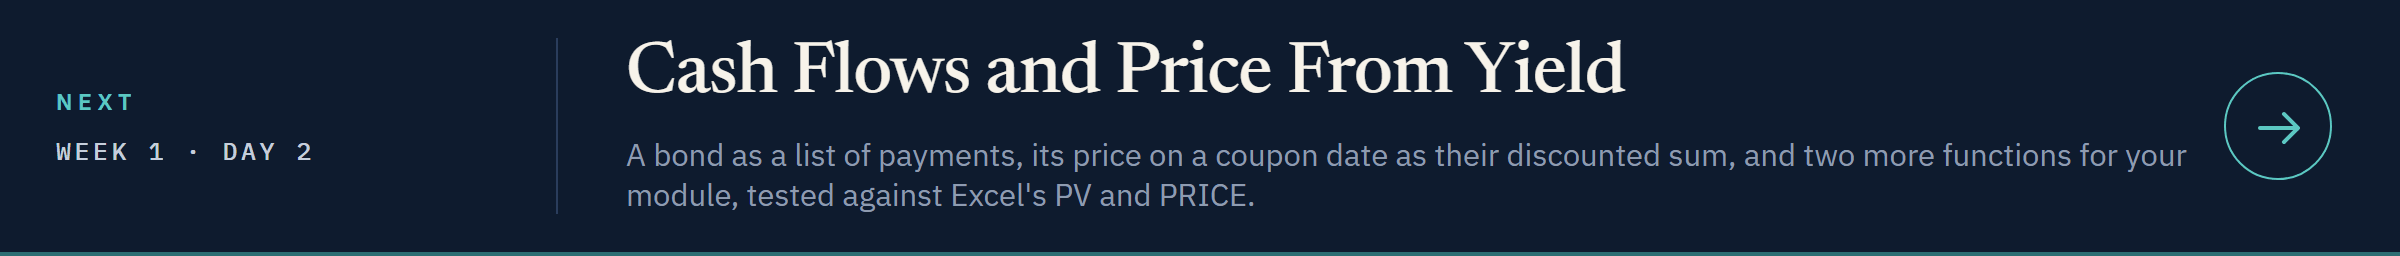](../day2/02_cash_flows_and_price_from_yield.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day2/02_cash_flows_and_price_from_yield.ipynb)